<a href="https://colab.research.google.com/github/Team-S-Hackathon-Group-RM/Team-S-Hackathon-Group-RM/blob/main/FINAL%20GroupS%20TownCost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COVID Vaccine Allocation: Minimising Town Cost (Dataset C)
### Data Science Challenge Hackathon, 11 November 2026, Group S

**GitHub organisation:** https://github.com/Team-S-Hackathon-Group-RM  
**Repository:** https://github.com/Team-S-Hackathon-Group-RM/Team-S-Hackathon-Group-RM
**Open in Colab:** https://colab.research.google.com/github/Team-S-Hackathon-Group-RM/Team-S-Hackathon-Group-RM/blob/main/FINAL%20GroupS%20TownCost.ipynb  
**Shared Colab (Editor):** to be added by the team

### Team members (Group S)
| # | Name | Notebook sections / role |
|---|---|---|
| 1 | Maruri Siva Harshitha | 2 EDA |
| 2 | Shruthi Chintalapudi | 2 EDA |
| 3 | Iqra Fazal | 3 Metric + AI hospitalisation research |
| 4 | Aqsa Iqbal | 4 Pre-processing, 5.1 |
| 5 | Kodi Chinthala Vaishnavi | 5–6 Models + calibration |
| 6 | Shravani Mukkarigari | 7–8 Tuning + ensemble |
| 7 | Lakshmi Nagaraju Manthri | 9 Results, variability, sensitivity |
| 8 | Varun Kumar Kashetty | 11–12 XAI, critical analysis, slides |
| 9 | Sai Raghavendra Ummareddy | absent from the hackathon on 11 Nov; no sections assigned |

**The task.** For every resident in the test set, decide whether to **post them a COVID vaccine (1) or not (0)**.
We are scored on the **total money the town spends**, not on accuracy:

* Vaccine: **$1,500** per dose sent (a dose nobody uses is wasted but still paid for).
* Anyone who wants a vaccine but is not sent one must be paid **$1,500 in cash** instead (and stays unvaccinated).
* Everyone is infected (100%). Each hospitalisation costs **$41,000**. The hospitalisation risk depends on the person and on whether they are vaccinated.

**Plan of the notebook**
1. Setup and data
2. Exploratory data analysis (EDA)
3. The task metric (town cost) and the optimal decision rule
4. Pre-processing (two variants)
5. Models, scored with repeated cross-validation (mean ± std)
6. Probability calibration
7. Hyper-parameter tuning
8. Ensemble
9. Decision rule comparison and sensitivity to the hospitalisation assumptions
10. Final ranking and the 5 submission files
11. Explainable AI (first version)
12. Critical analysis

*Integrator (sections 1 and 10, GitHub setup, Canvas upload): one of the members above, to be chosen by the team.*

## 0. Team guidelines (read first)

**Deadline today: upload to Canvas at 15:40** (hard deadline 16:00), assignment *"Data Science Challenge Hackathon submissions"*: the 5 files in `submission/` + link to the GitHub organisation + link to this Colab.

### Who does what (suggested split; change if the team decides otherwise)
| Pair | Sections of this notebook | Task |
|---|---|---|
| Integrator: ____ (choose one) | 1, 10 | GitHub/Colab setup, final *Restart and run all* at 15:15, submission files, Canvas upload |
| EDA: Maruri Siva Harshitha & Shruthi Chintalapudi | 2 | more plots that justify pre-processing and model choices |
| Metric: Iqra Fazal | 3 | ask 2–3 different AIs for hospitalisation probabilities, fill the table in 3.3 and the values in the code |
| Pre-processing: Aqsa Iqbal | 4, 5.1 | try other options (binning, imputation, encoding), compare with the town cost |
| Models: Kodi Chinthala Vaishnavi | 5, 6 | add models (e.g. XGBoost, MLP), scored with `evaluate()` |
| Tuning / ensemble: Shravani Mukkarigari · Results: Lakshmi Nagaraju Manthri | 7, 8, 9 | tuning, variability (box plot, paired comparison), sensitivity |
| XAI + slides: Varun Kumar Kashetty | 11, 12 | XAI for **all** models, figure styling, presentation (may continue after 16:00) |

### Rules for working in this shared notebook
1. Work only in **your own section**. Add new cells inside it, never in someone else's.
2. Put your name in every markdown heading you add, e.g. `### 2.6 Income vs vaccination (YourName)`.
3. **Do not press Run all** while others are working. Run your own cells (run sections 1, 3 and 4 once first, so `train`, `X`, `y`, `hosp_probs` and `evaluate` exist).
4. Every model must be scored with **`evaluate()`**: town cost per resident, mean ± std over the same 15 CV folds. Never rank by accuracy, F1 or AUC alone.
5. Every plot that will go in the slides must be produced by code in this notebook (1 point lost per plot without code).
6. Explain each step in a markdown cell: **what** you did and **why**.
7. After finishing a piece of work, push it to GitHub **from your own account**: *File → Save a copy in GitHub* → org repo, path `FINAL GroupS TownCost.ipynb`, branch `main`, message saying what you did (e.g. `Pre-processing: binning comparison (YourName)`). Commit every 30–45 min.
8. After 16:00 only **XAI and figure styling** may change. No new models or pre-processing.

### Timeline today
| Time | Milestone |
|---|---|
| by 11:45 | GitHub org + public repo + Colab shared (Editor) + names filled in above |
| by 12:30 | AI hospitalisation answers in 3.3 |
| 12:30–15:00 | each pair extends its sections and pushes |
| 15:00 | stop adding models; everything must be scored with `evaluate()` |
| 15:15 | integrator: *Runtime → Restart and run all*, check 5 files, push notebook with outputs |
| **15:40** | **Canvas upload** (second person confirms) |

### Submission requirements (checked automatically in section 10)
* 5 **different** files, named `challenge_submission_group_S_order_1.csv` … `_order_5.csv`, order 1 = lowest town cost.
* Same format as `dataset_C_example_submission.csv`: columns `respondent_id`, `covid_vaccine` (1 = send a vaccine, 0 = don't), all 4,749 test IDs in the same order.

### For the presentation (Tue 17 Nov; slides due 10:00, talks from 13:00)
* Slide 1: **GitHub organisation URL + this Colab URL**.
* 10 minutes hard stop, then 5 min questions; **every member presents** and must be able to answer questions on the **whole** project.
* Must include: model architecture and training scheme, EDA, performance with the town cost, XAI, successes and failures, how we divided work and made decisions, and **one slide for non-experts** (plain language, no jargon).

Full details: `docs/HOW_TO_PUSH.md` (**step-by-step push instructions for every member**), `docs/CHECKLIST.md` (every requirement) and `docs/GITHUB_GUIDE.md` (GitHub workflow).

## 1. Setup and data

> 👤 **Section owner:** Integrator: ____ (choose one)  
> 📌 **Section rules:** Only the integrator edits this section. Keep `SEED = 42`. Do not change file names or the `GITHUB_DATA` link.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `Setup:` and ends with your name.

In [ ]:
# Colab already has these libraries; install any that are missing (no effect when running locally)
import importlib.util, subprocess, sys
missing = [pkg for pkg in ('lightgbm', 'shap', 'seaborn') if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)

# Standard imports; every random process uses SEED so results reproduce exactly.
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from lightgbm import LGBMClassifier

SEED = 42
TARGET, ID = 'covid_vaccine', 'respondent_id'
GROUP = 'S'
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

In [ ]:
# Load data. In Colab the files are read straight from our public GitHub repo (the brief asks for Colab
# to be linked to the data on GitHub). Fallbacks: a local data/ folder (cloned repo) or files uploaded to the session.
import os
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
GITHUB_DATA = 'https://raw.githubusercontent.com/Team-S-Hackathon-Group-RM/Team-S-Hackathon-Group-RM/main/data/'   # change if the repo name differs

def load_csv(name):
    places = ([GITHUB_DATA] if IN_COLAB else []) + ['data/', '']
    for base in places:
        try:
            frame = pd.read_csv(base + name)
            print(f'loaded {name} from {base or "the current folder"}')
            return frame
        except Exception:
            continue
    raise FileNotFoundError(f'{name} not found. In Colab: check GITHUB_DATA and that the repo is public, '
                            'or upload the three CSV files with the folder icon on the left.')

train   = load_csv('dataset_C_training.csv')
test    = load_csv('dataset_C_testing.csv')
example = load_csv('dataset_C_example_submission.csv')
y = train[TARGET].values
print('train', train.shape, '| test', test.shape, '| example', example.shape, list(example.columns))
train.head()

loaded dataset_C_training.csv from data/
loaded dataset_C_testing.csv from data/
loaded dataset_C_example_submission.csv from data/
train (4756, 31) | test (4749, 30) | example (4749, 2) ['respondent_id', 'covid_vaccine']


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


### 1.1 Data cleaning: values outside the sheet's ranges
The dataset sheet defines the three opinion scales as **1-5**. In this file `opinion_covid_vacc_effective` and `opinion_covid_risk` also contain the value **0** (about 2% of rows, in both train and test), and most of those rows also have `opinion_covid_sick_from_vacc` missing. A 0 is not a valid answer, so it is treated as a missing value. Left as 0, it would sit "below Very low" on the scale and distort both the linear models and `doc_x_risk`.

`doctor_recc_covid` has no missing values at all here, although the other datasets had about 7% missing; missing answers may have been recorded as 0 (= not recommended). That cannot be checked, so it is noted as a limitation (section 12).

In [ ]:
SHEET_RANGE = {'covid_concern': (0, 3), 'covid_knowledge': (0, 2), 'opinion_covid_vacc_effective': (1, 5),
               'opinion_covid_risk': (1, 5), 'opinion_covid_sick_from_vacc': (1, 5),
               'household_adults': (0, 3), 'household_children': (0, 3), 'number_chronic_med_conditions': (0, 8)}
for df_name, df in [('train', train), ('test', test)]:
    for c, (lo, hi) in SHEET_RANGE.items():
        bad = df[c].notna() & ~df[c].between(lo, hi)
        if bad.any():
            print(f'{df_name}: {c} has {bad.sum()} values outside {lo}-{hi} ({sorted(df.loc[bad, c].unique())}) -> set to missing')
            df.loc[bad, c] = np.nan
y = train[TARGET].values

train: opinion_covid_vacc_effective has 92 values outside 1-5 ([np.int64(0)]) -> set to missing
train: opinion_covid_risk has 96 values outside 1-5 ([np.int64(0)]) -> set to missing
test: opinion_covid_vacc_effective has 107 values outside 1-5 ([np.int64(0)]) -> set to missing
test: opinion_covid_risk has 104 values outside 1-5 ([np.int64(0)]) -> set to missing


## 2. Exploratory data analysis

> 👤 **Section owner:** Maruri Siva Harshitha & Shruthi Chintalapudi  
> 📌 **Section rules:** Every plot needs a markdown sentence saying **what it shows and which decision it supports** (pre-processing or model). Use `train` only, never `test`. All plotting code stays here (−1 pt per slide plot without code).  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `EDA:` and ends with your name.

In [ ]:
# One visual theme for every EDA figure: muted background, light grid, left-aligned bold titles,
# and the same two colours throughout (red = vaccinated, blue = not vaccinated).
from matplotlib.colors import ListedColormap
PAL = {'yes': '#C8553D', 'no': '#2B6F8E', 'neutral': '#8D99AE', 'accent': '#F2A541', 'ink': '#1F2933'}
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': '#FBFBF8', 'axes.edgecolor': '#C9CED6',
    'axes.grid': True, 'grid.color': '#E6E8EB', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left', 'axes.labelcolor': PAL['ink'],
    'font.size': 10, 'legend.frameon': False, 'figure.dpi': 110})
print('EDA theme set')

EDA theme set


### 2.1 Target balance
About one in three respondents accepted the vaccine, so the classes are imbalanced. Every vaccine we post to a refuser costs $1,500, so knowing *who* accepts matters.

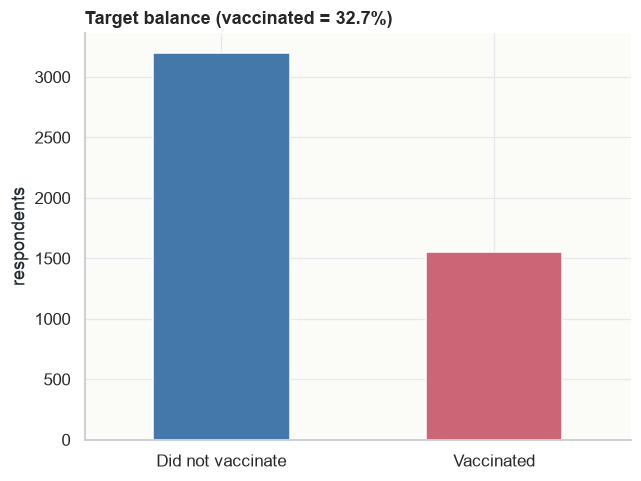

In [ ]:
rate = y.mean()
ax = pd.Series(y).map({0: 'Did not vaccinate', 1: 'Vaccinated'}).value_counts().plot(kind='bar', color=['#4477aa', '#cc6677'])
ax.set_title(f'Target balance (vaccinated = {rate:.1%})'); ax.set_ylabel('respondents'); plt.xticks(rotation=0); plt.show()

### 2.2 Missing values
`employment_sector` and `health_insurance` are missing for 40-50% of people. Missingness itself may carry information (e.g. unemployed people have no sector), so tree models keep NaN as its own value and the linear model gets missing-value indicators.

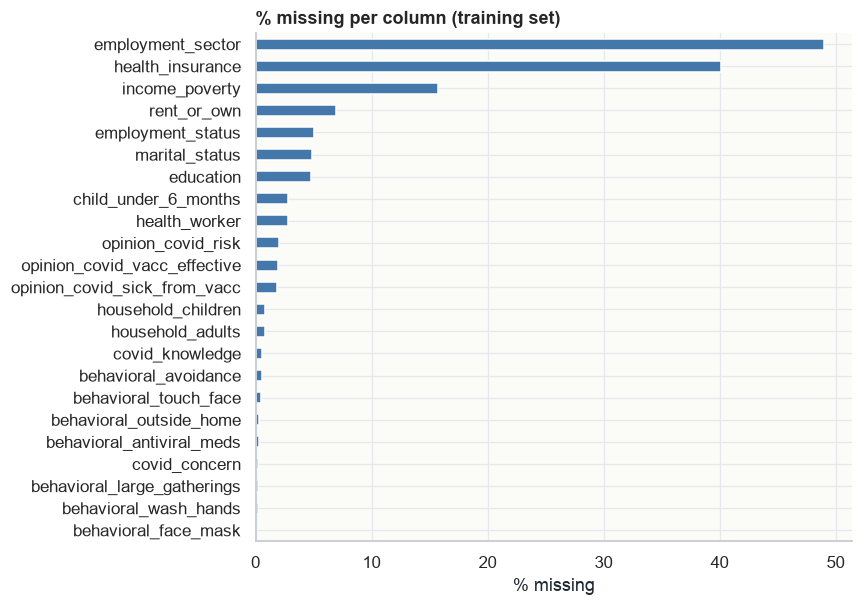

employment_sector       49.0
health_insurance        40.1
income_poverty          15.7
rent_or_own              6.9
employment_status        5.0
marital_status           4.9
education                4.8
child_under_6_months     2.8


In [ ]:
miss = (train.isna().mean() * 100).sort_values()
miss = miss[miss > 0]
ax = miss.plot(kind='barh', figsize=(7, 6), color='#4477aa')
ax.set_title('% missing per column (training set)'); ax.set_xlabel('% missing'); plt.show()
print(miss.round(1).sort_values(ascending=False).head(8).to_string())

### 2.3 Vaccination rate by key features
These plots guide both the acceptance model and the hospitalisation-risk part of the metric (age and chronic conditions).

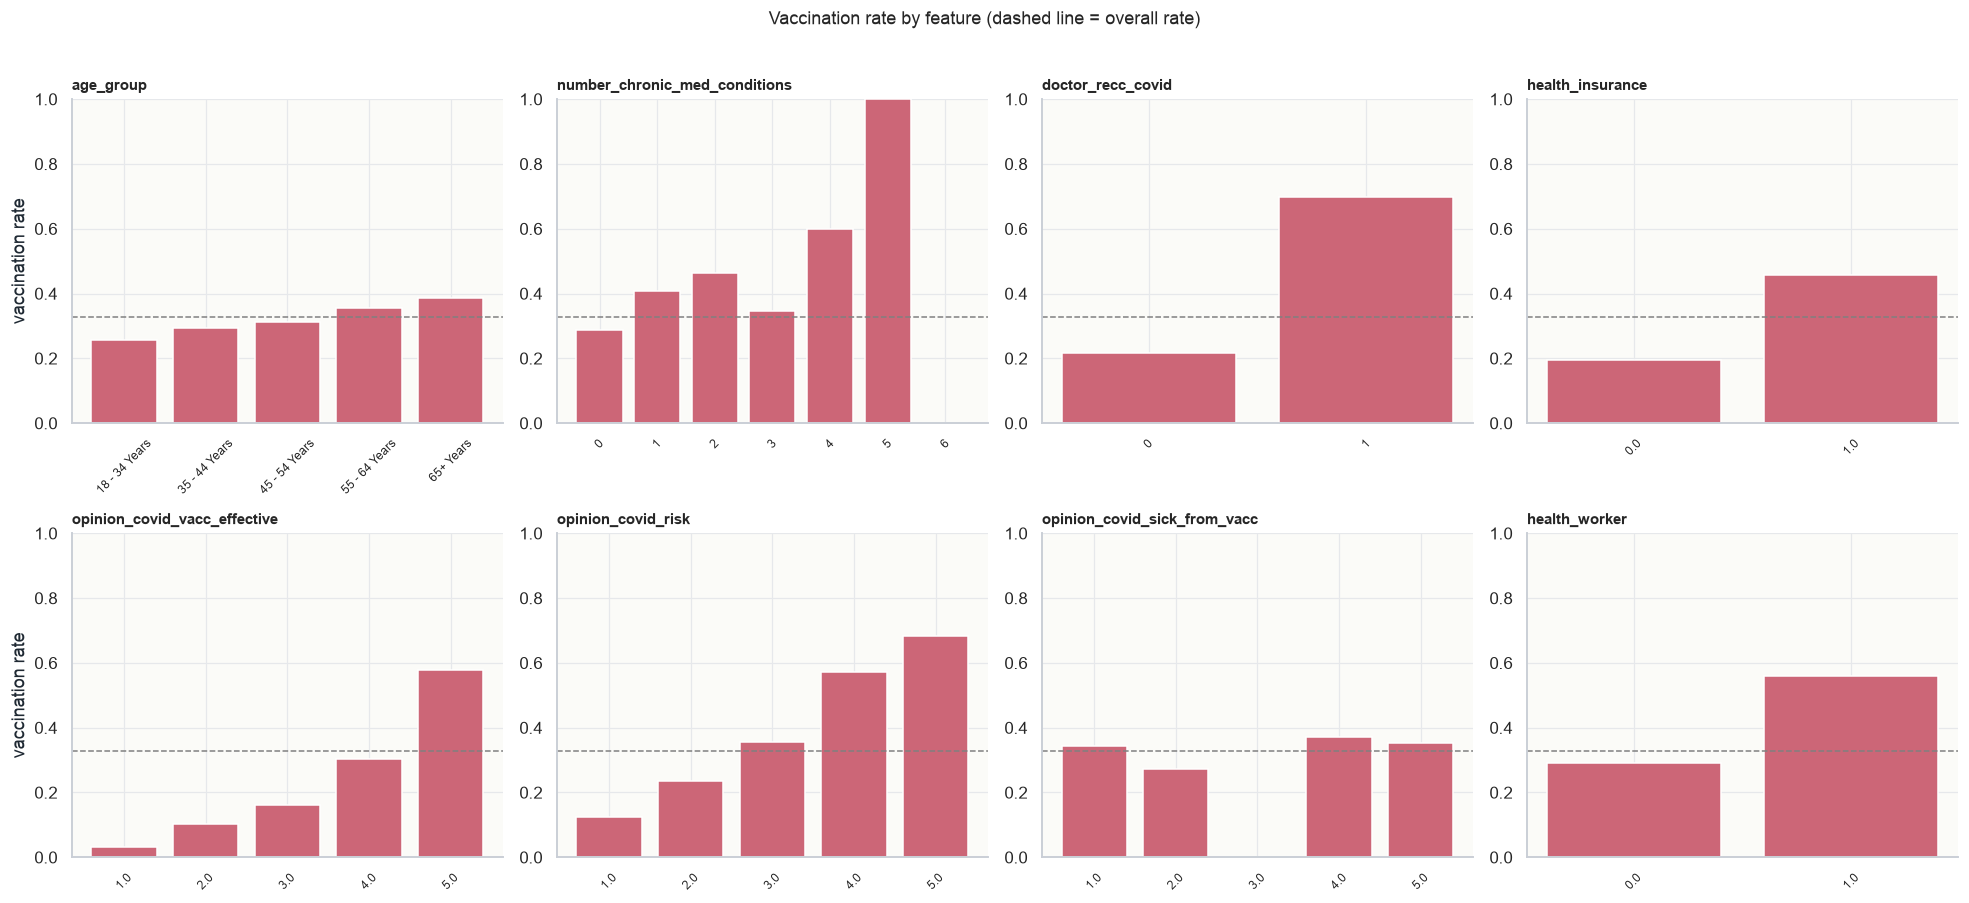

In [ ]:
cols = ['age_group', 'number_chronic_med_conditions', 'doctor_recc_covid', 'health_insurance',
        'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'health_worker']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cols):
    g = train.groupby(train[c].astype(str))[TARGET].agg(['mean', 'size'])
    ax.bar(g.index, g['mean'], color='#cc6677')
    ax.axhline(rate, ls='--', c='grey', lw=1)
    ax.set_title(c, fontsize=10); ax.set_ylim(0, 1); ax.tick_params(axis='x', rotation=45, labelsize=8)
axes[0, 0].set_ylabel('vaccination rate'); axes[1, 0].set_ylabel('vaccination rate')
plt.suptitle('Vaccination rate by feature (dashed line = overall rate)', y=1.02); plt.tight_layout(); plt.show()

### 2.4 Correlation of numeric features with the target

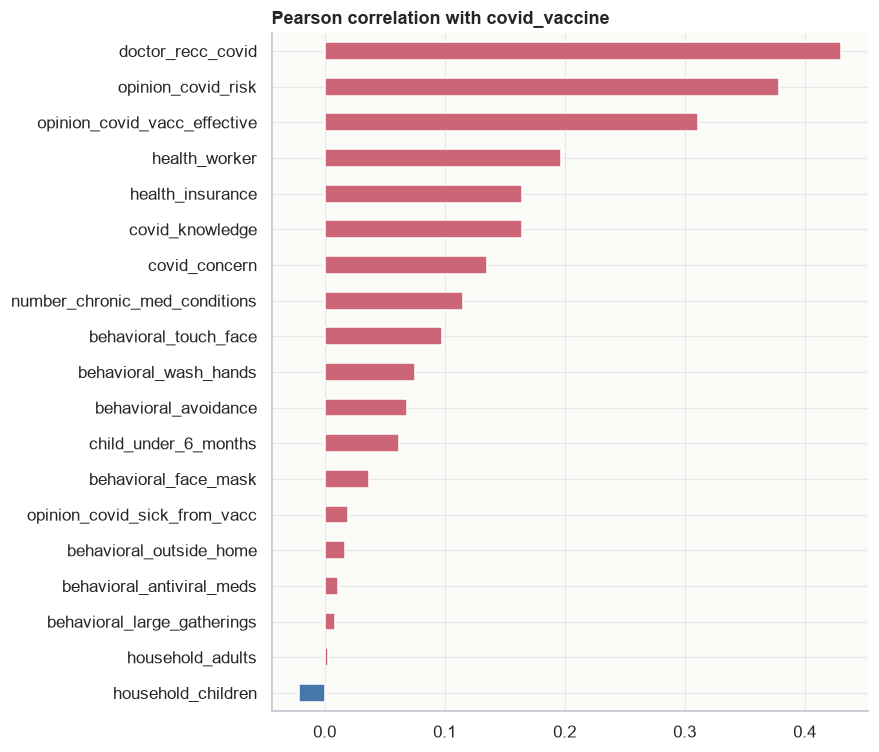

In [ ]:
num_corr = train.drop(columns=[ID]).select_dtypes('number').corr()[TARGET].drop(TARGET).sort_values()
ax = num_corr.plot(kind='barh', figsize=(7, 8), color=np.where(num_corr > 0, '#cc6677', '#4477aa'))
ax.set_title('Pearson correlation with covid_vaccine'); plt.show()

### 2.5 Age and chronic conditions together
Older people and people with more chronic conditions are both more likely to vaccinate *and* more likely to be hospitalised, so they matter twice for the town cost.

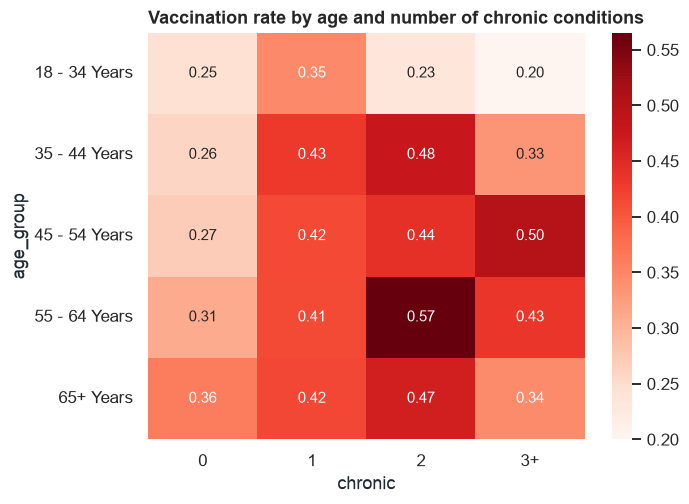

In [ ]:
pivot = train.assign(chronic=train['number_chronic_med_conditions'].clip(upper=3).astype(str).replace({'3': '3+'})) \
             .pivot_table(index='age_group', columns='chronic', values=TARGET, aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='Reds'); plt.title('Vaccination rate by age and number of chronic conditions'); plt.show()

### 2.6 Data overview and integrity checks
Before any plot: data types, number of distinct values, missing share and example values for every column, plus duplicate and ID checks.

In [ ]:
from scipy.stats import chi2_contingency
FEATS = [c for c in train.columns if c not in (ID, TARGET)]          # the 29 input features
CATS = [c for c in FEATS if not pd.api.types.is_numeric_dtype(train[c])]   # text categoricals (works with pandas 2 and 3)
ORDS = [c for c in FEATS if c not in CATS]                           # binary / ordinal / count features

overview = pd.DataFrame({
    'dtype': train[FEATS].dtypes.astype(str),
    'type': ['categorical (text)' if c in CATS else ('binary' if train[c].nunique() == 2 else 'ordinal / count') for c in FEATS],
    'n_unique': train[FEATS].nunique(),
    'missing %': (train[FEATS].isna().mean() * 100).round(1),
    'example values': [', '.join(map(str, train[c].dropna().unique()[:4])) for c in FEATS]})
display(overview)

print('Duplicate rows (ignoring ID):', train.drop(columns=[ID]).duplicated().sum())
print('IDs unique in train:', train[ID].is_unique, '| in test:', test[ID].is_unique,
      '| train/test ID overlap:', len(set(train[ID]) & set(test[ID])))
print('Test has the same feature columns as train:', list(test.columns) == [c for c in train.columns if c != TARGET])
print(f'{len(CATS)} text categoricals, {len(ORDS)} binary/ordinal/count features, target = {TARGET}')

,dtype,type,n_unique,missing %,example values
covid_concern,float64,ordinal / count,4,0.3,"3.0, 2.0, 0.0, 1.0"
covid_knowledge,float64,ordinal / count,3,0.6,"1.0, 2.0, 0.0"
behavioral_antiviral_meds,float64,binary,2,0.3,"0.0, 1.0"
behavioral_avoidance,float64,binary,2,0.6,"1.0, 0.0"
behavioral_face_mask,float64,binary,2,0.0,"0.0, 1.0"
behavioral_wash_hands,float64,binary,2,0.2,"1.0, 0.0"
behavioral_large_gatherings,float64,binary,2,0.2,"0.0, 1.0"
behavioral_outside_home,float64,binary,2,0.3,"1.0, 0.0"
behavioral_touch_face,float64,binary,2,0.4,"1.0, 0.0"
child_under_6_months,float64,binary,2,2.8,"0.0, 1.0"


Duplicate rows (ignoring ID): 0
IDs unique in train: True | in test: True | train/test ID overlap: 0
Test has the same feature columns as train: True
10 text categoricals, 19 binary/ordinal/count features, target = covid_vaccine


### 2.7 Distribution of every feature
Grey bars = missing values. This shows the shape of each variable (skew, rare levels, top-coding) and which ones need imputation or grouping.

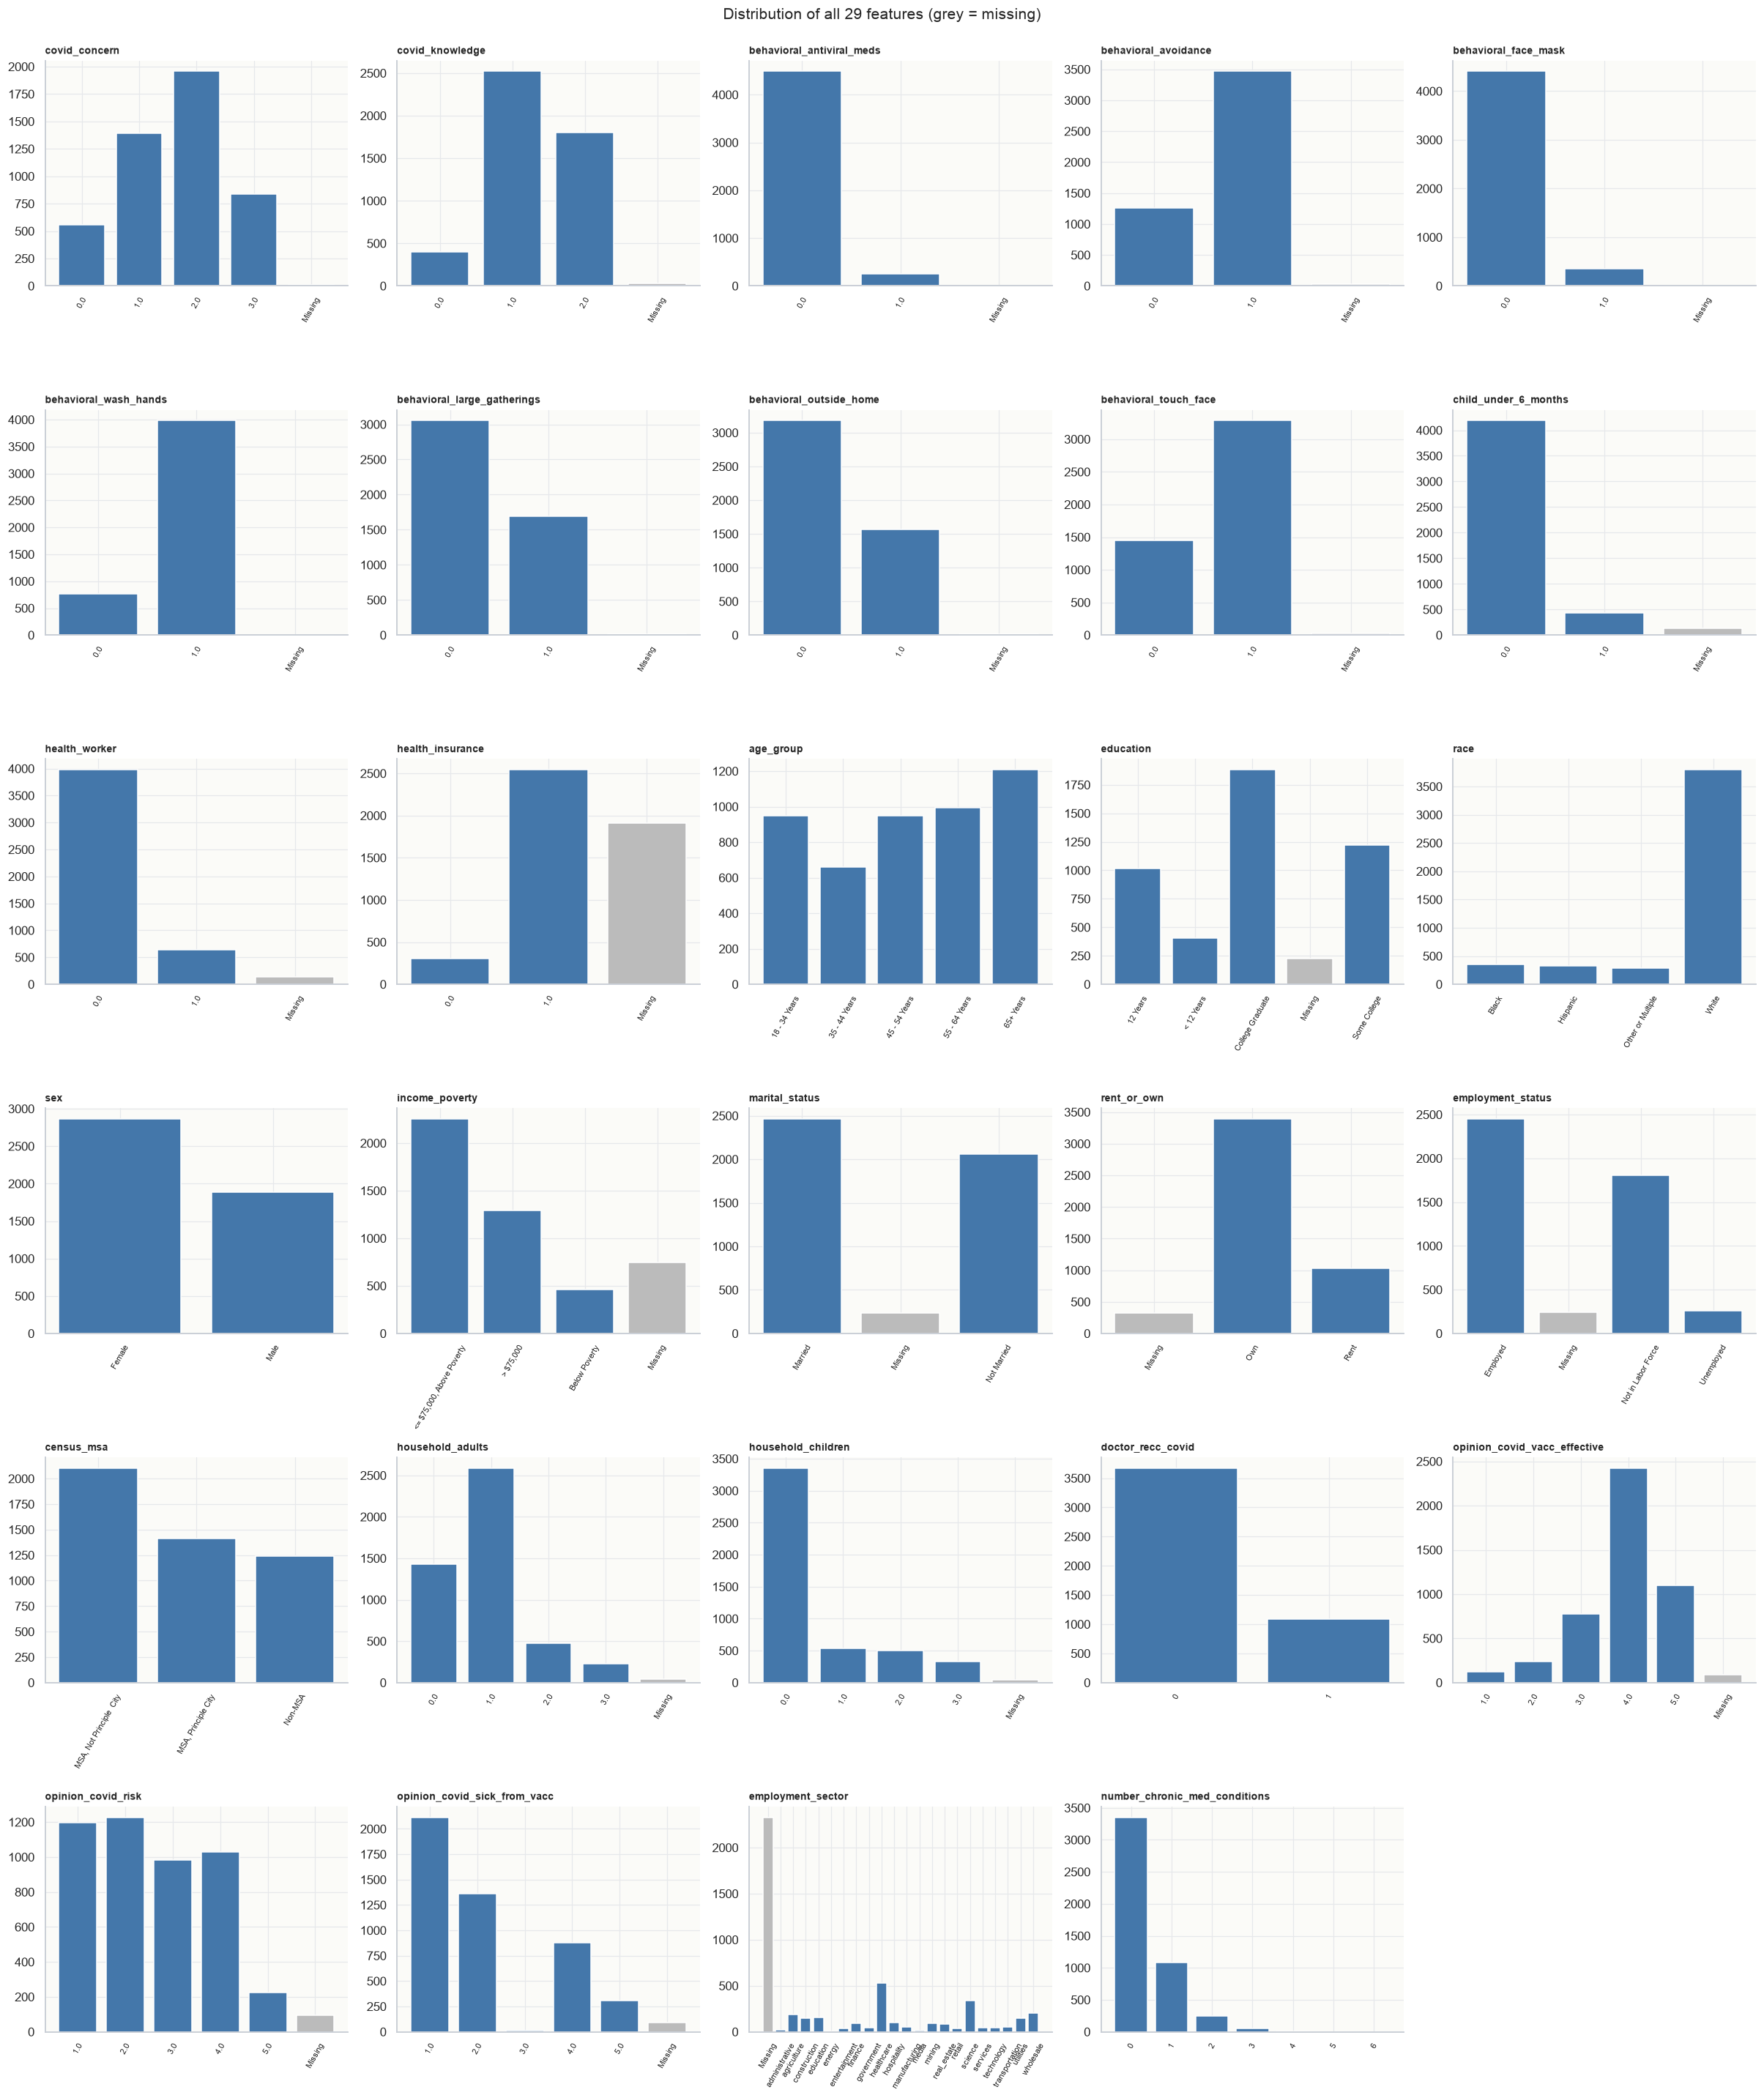

In [ ]:
fig, axes = plt.subplots(6, 5, figsize=(22, 26))
for ax, c in zip(axes.ravel(), FEATS):
    vc = train[c].astype(str).where(train[c].notna(), 'Missing').value_counts().sort_index()
    ax.bar(vc.index, vc.values, color=['#bbbbbb' if i == 'Missing' else '#4477aa' for i in vc.index])
    ax.set_title(c, fontsize=9); ax.tick_params(axis='x', rotation=60, labelsize=7)
for ax in axes.ravel()[len(FEATS):]:
    ax.axis('off')
plt.suptitle('Distribution of all 29 features (grey = missing)', y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

### 2.8 Vaccination rate for every categorical feature (with 95% confidence intervals)
Error bars show how much each rate could move by chance; small groups have wide bars and should not drive decisions on their own.

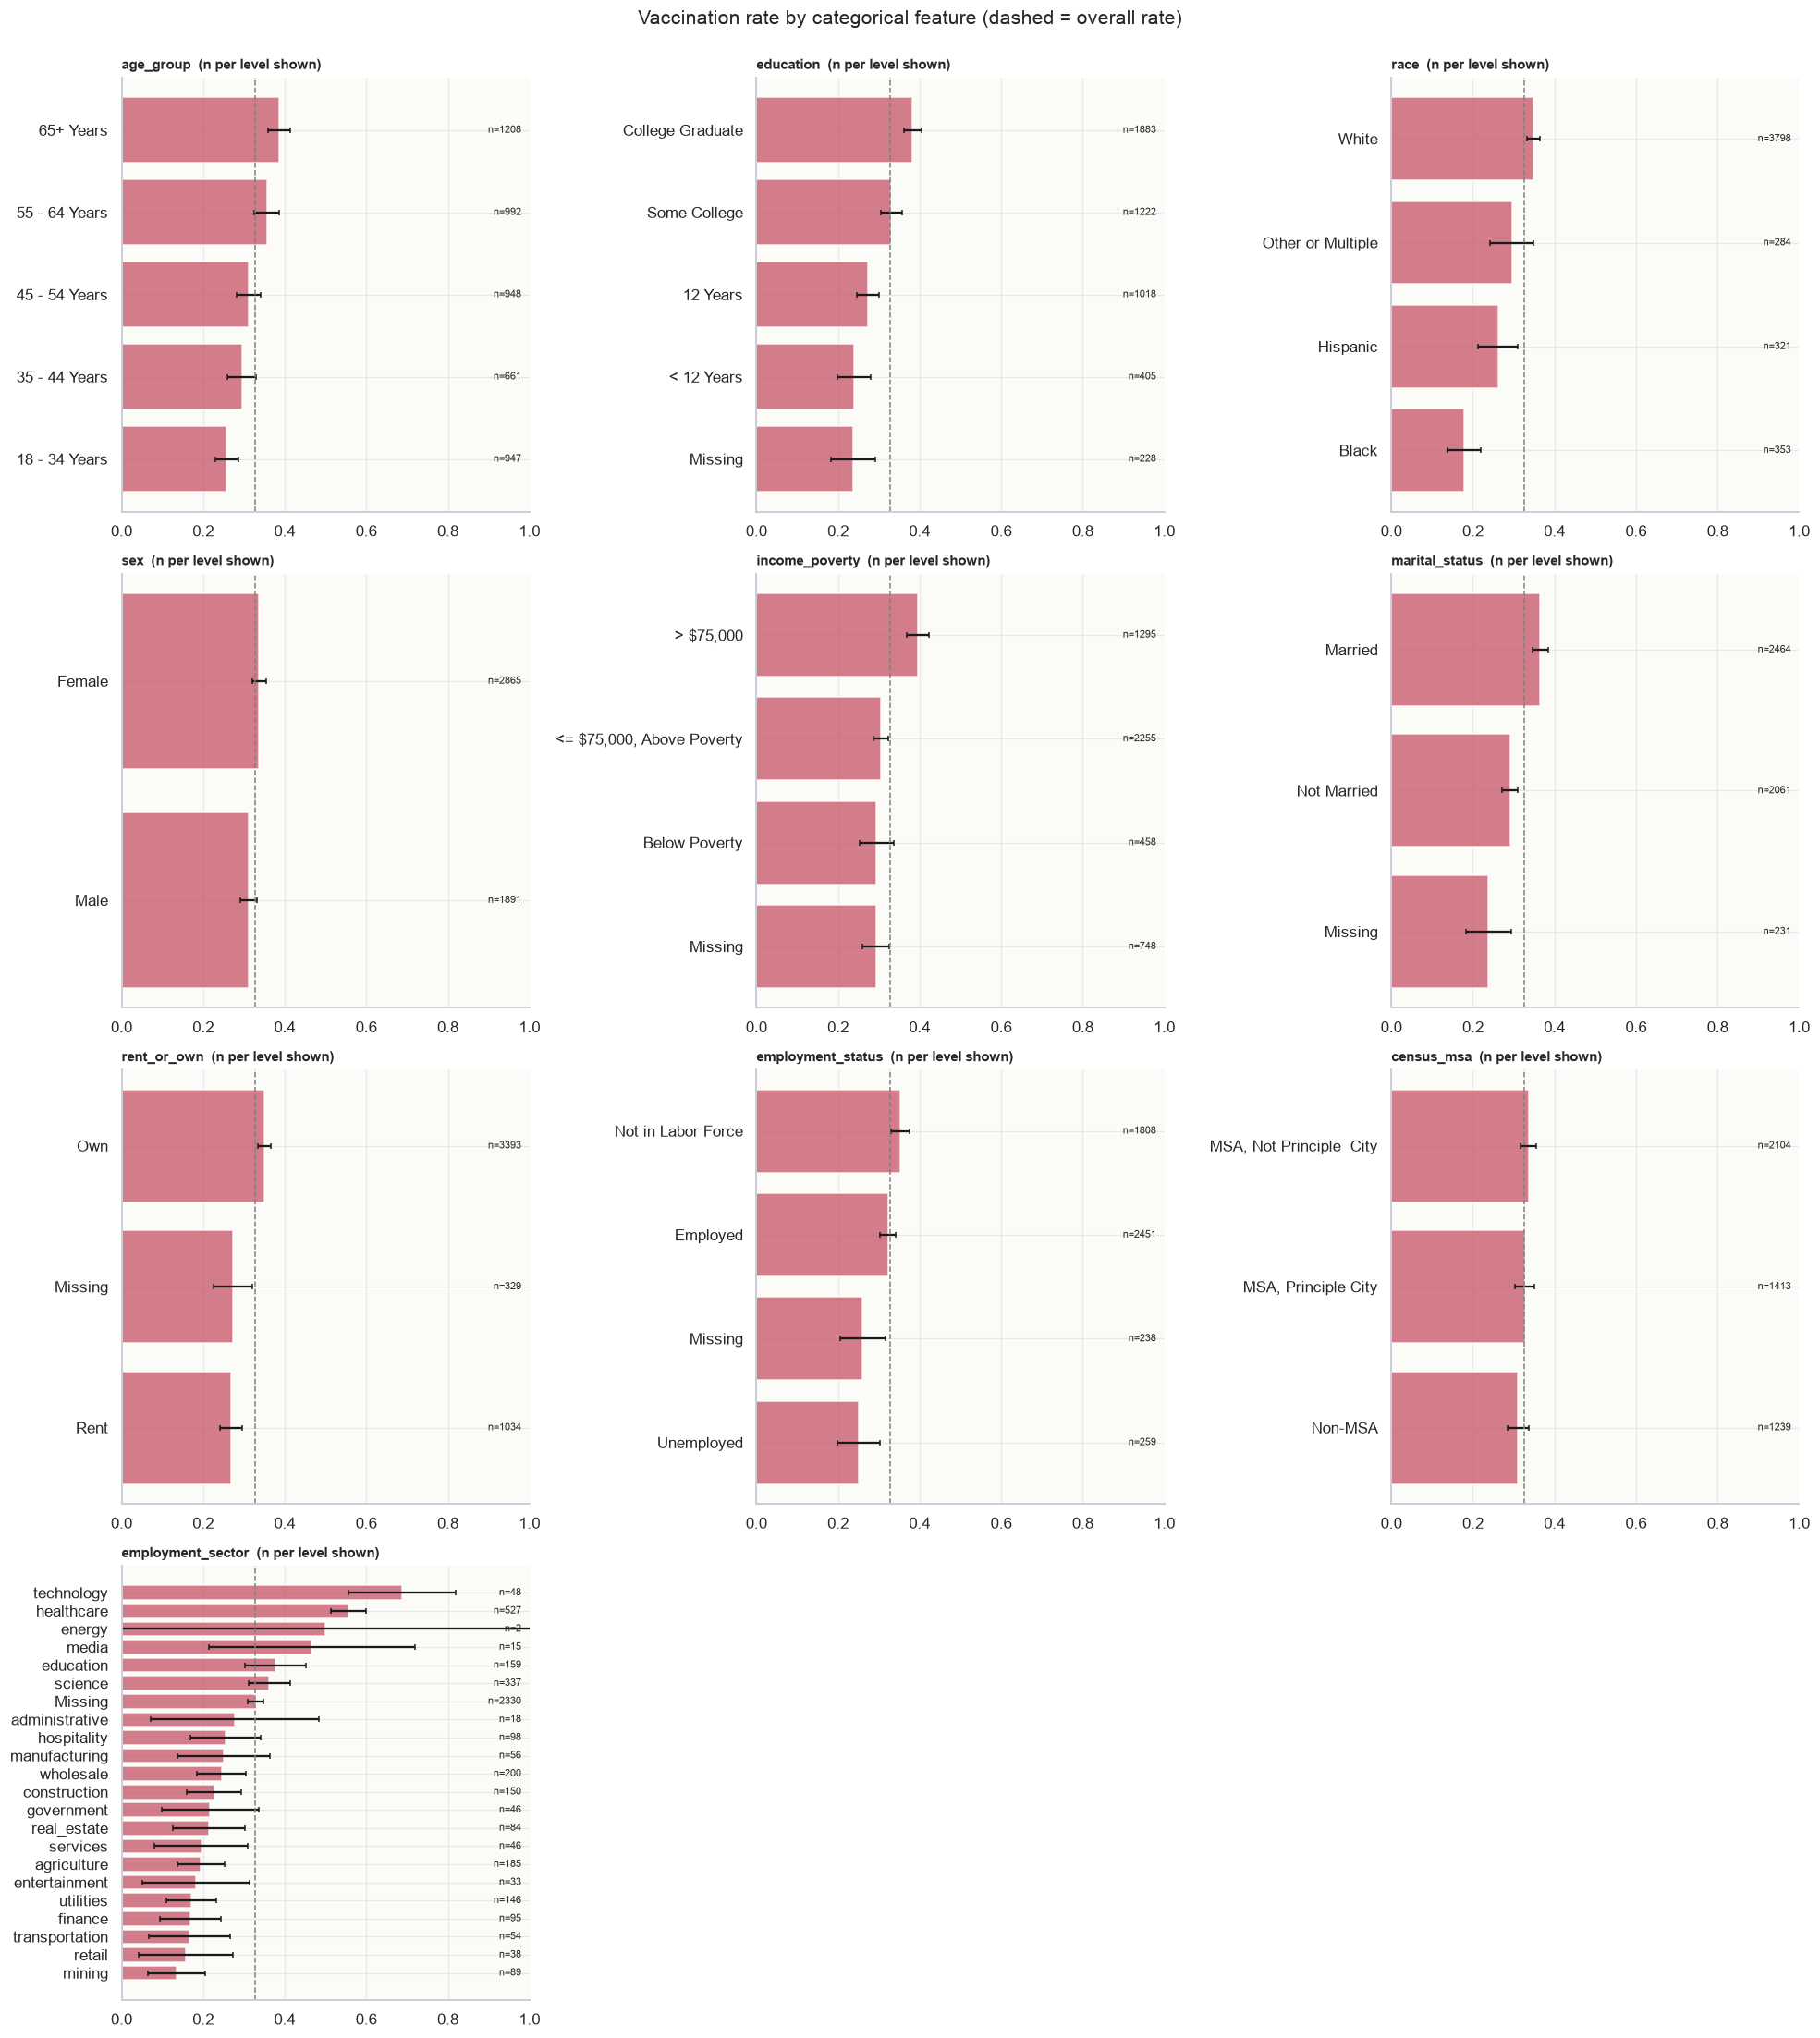

In [ ]:
def rate_table(col):
    s = train[col].astype(str).where(train[col].notna(), 'Missing')
    g = train.groupby(s)[TARGET].agg(['mean', 'size'])
    g['ci95'] = 1.96 * np.sqrt(g['mean'] * (1 - g['mean']) / g['size'])
    return g.sort_values('mean')

fig, axes = plt.subplots(4, 3, figsize=(18, 20))
for ax, c in zip(axes.ravel(), CATS):
    g = rate_table(c)
    ax.barh(g.index, g['mean'], xerr=g['ci95'], color='#cc6677', alpha=0.85, capsize=2)
    ax.axvline(rate, ls='--', c='grey', lw=1)
    ax.set_title(f'{c}  (n per level shown)', fontsize=10); ax.set_xlim(0, 1)
    for i, (m, k) in enumerate(zip(g['mean'], g['size'])):
        ax.text(0.98, i, f'n={k}', va='center', ha='right', fontsize=7)
for ax in axes.ravel()[len(CATS):]:
    ax.axis('off')
plt.suptitle('Vaccination rate by categorical feature (dashed = overall rate)', y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

### 2.9 Missing data: patterns and link with the target
(a) Which columns go missing **together**. (b) Whether people with a missing value vaccinate at a **different rate** (chi-square test). If they do, missingness is information and should be kept, not imputed away.

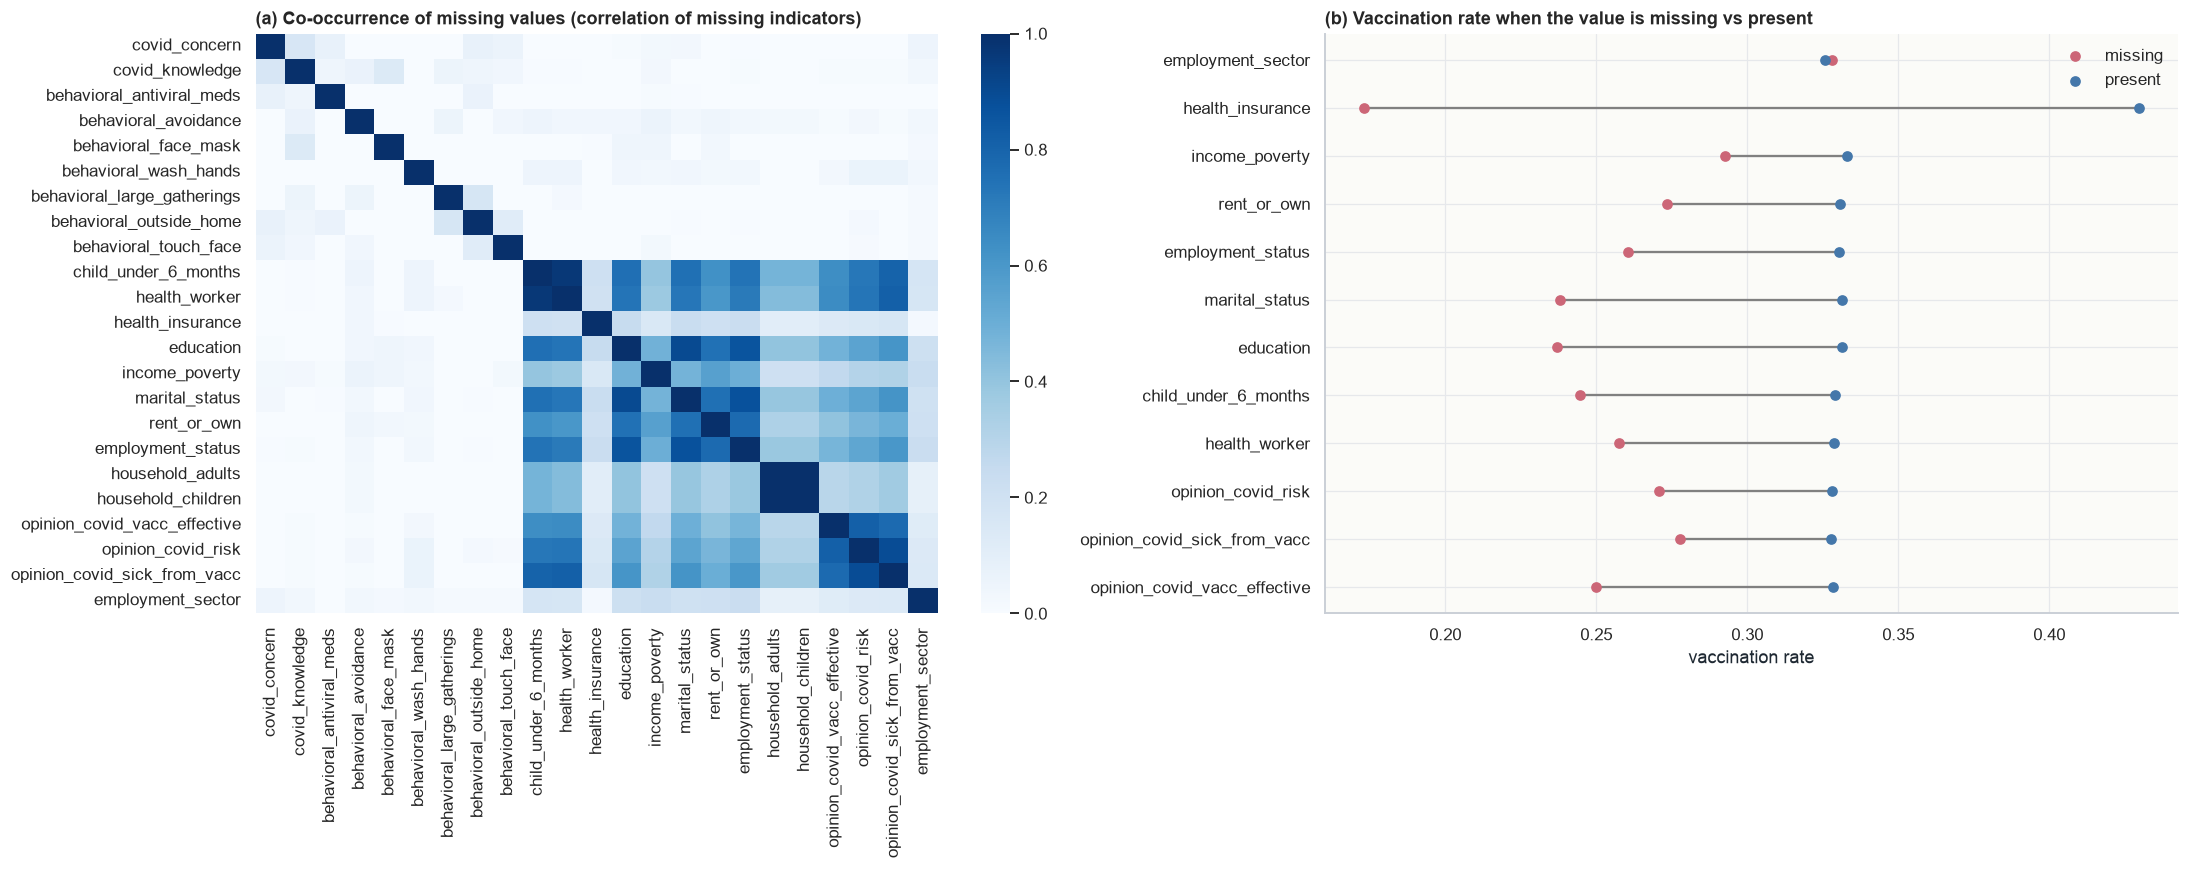

,column,missing %,rate if missing,rate if present,chi2 p-value
0,employment_sector,49.000000,0.328,0.326,8.93e-01
1,health_insurance,40.100000,0.173,0.430,3.16e-76
2,income_poverty,15.700000,0.293,0.333,3.44e-02
3,rent_or_own,6.900000,0.274,0.331,3.83e-02
4,employment_status,5.000000,0.261,0.330,3.04e-02
5,marital_status,4.900000,0.238,0.331,4.06e-03
6,education,4.800000,0.237,0.331,3.80e-03
7,child_under_6_months,2.800000,0.244,0.329,4.82e-02
8,health_worker,2.800000,0.258,0.329,1.04e-01
9,opinion_covid_risk,2.000000,0.271,0.328,2.85e-01


Columns where missingness is significantly linked to vaccination (p < 0.01): ['health_insurance', 'marital_status', 'education']


In [ ]:
mcols = [c for c in FEATS if train[c].isna().any()]
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(train[mcols].isna().astype(int).corr(), cmap='Blues', vmin=0, vmax=1, ax=axes[0])
axes[0].set_title('(a) Co-occurrence of missing values (correlation of missing indicators)')

rows = []
for c in mcols:
    m = train[c].isna()
    rows.append({'column': c, 'missing %': round(m.mean() * 100, 1),
                 'rate if missing': train.loc[m, TARGET].mean(), 'rate if present': train.loc[~m, TARGET].mean(),
                 'chi2 p-value': chi2_contingency(pd.crosstab(m, train[TARGET]))[1]})
miss_tbl = pd.DataFrame(rows).sort_values('missing %', ascending=False).reset_index(drop=True)
top = miss_tbl.head(12).iloc[::-1]
axes[1].hlines(top['column'], top['rate if missing'], top['rate if present'], color='grey')
axes[1].scatter(top['rate if missing'], top['column'], color='#cc6677', label='missing', zorder=3)
axes[1].scatter(top['rate if present'], top['column'], color='#4477aa', label='present', zorder=3)
axes[1].set_title('(b) Vaccination rate when the value is missing vs present'); axes[1].legend(); axes[1].set_xlabel('vaccination rate')
plt.tight_layout(); plt.show()
display(miss_tbl.style.format({'rate if missing': '{:.3f}', 'rate if present': '{:.3f}', 'chi2 p-value': '{:.2e}'}))
print('Columns where missingness is significantly linked to vaccination (p < 0.01):',
      miss_tbl.loc[miss_tbl['chi2 p-value'] < 0.01, 'column'].tolist())

### 2.10 Associations between features
Spearman correlation for binary/ordinal features (left) and Cramér's V for categorical features and the target (right). Only one pair turns out to be strongly related (large gatherings and outside home); the behaviour flags are mostly weak, separate signals, so `behavioral_count` is tested as a way to combine several weak signals (section 5.1).

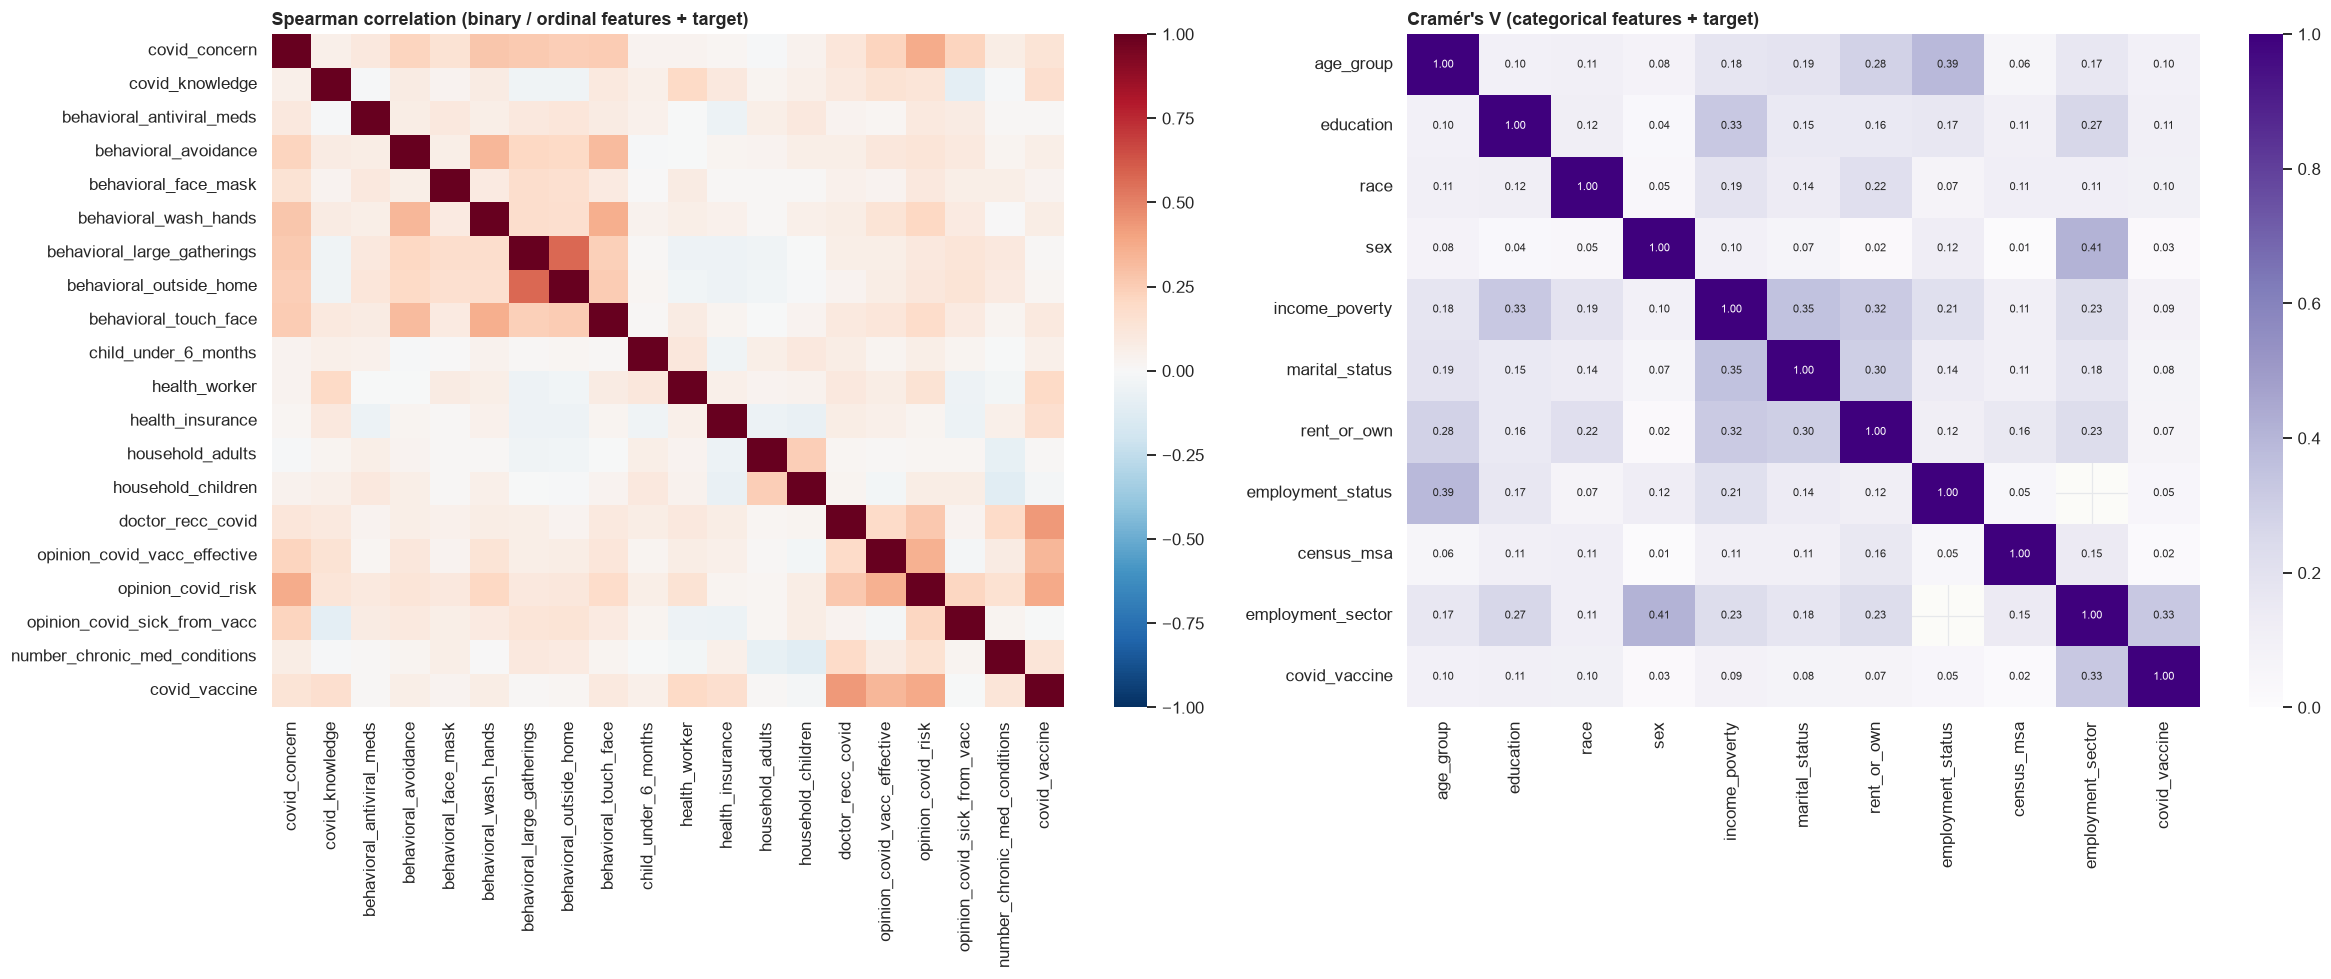

Most strongly related feature pairs (|Spearman| > 0.4):
behavioral_large_gatherings  behavioral_outside_home    0.58


In [ ]:
def cramers_v(a, b):
    ct = pd.crosstab(a.astype(str), b.astype(str))
    chi2 = chi2_contingency(ct, correction=False)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
spear = train[ORDS + [TARGET]].corr(method='spearman')
sns.heatmap(spear, cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Spearman correlation (binary / ordinal features + target)')

cv_cols = CATS + [TARGET]
cv_mat = pd.DataFrame([[cramers_v(train[a], train[b]) for b in cv_cols] for a in cv_cols], index=cv_cols, columns=cv_cols)
sns.heatmap(cv_mat, annot=True, fmt='.2f', cmap='Purples', vmin=0, vmax=1, ax=axes[1], annot_kws={'size': 7})
axes[1].set_title("Cramér's V (categorical features + target)")
plt.tight_layout(); plt.show()

pairs = spear.drop(index=TARGET, columns=TARGET).where(np.triu(np.ones((len(ORDS), len(ORDS)), bool), k=1)).stack()
print('Most strongly related feature pairs (|Spearman| > 0.4):')
print(pairs[pairs.abs() > 0.4].sort_values(key=abs, ascending=False).round(2).to_string())

### 2.11 Which features carry the most information about vaccination?
Mutual information (captures any relationship, not just linear) and a chi-square test for every feature, with missing treated as its own level.

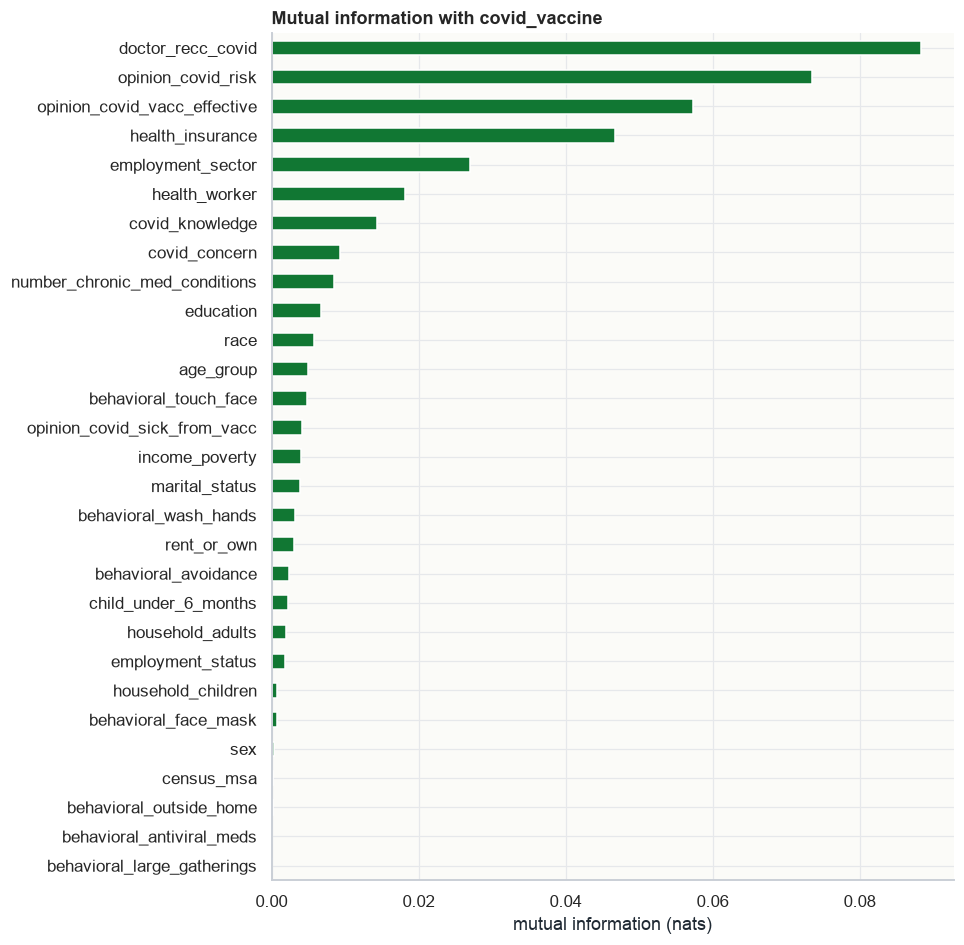

,mutual information,chi2 p-value
doctor_recc_covid,0.0883,4.1e-193
opinion_covid_risk,0.0735,6.3e-147
opinion_covid_vacc_effective,0.0573,1.6e-111
health_insurance,0.0468,2.7e-18
employment_sector,0.0271,2.0e-43
health_worker,0.0181,9.8e-41
covid_knowledge,0.0143,2.1e-30
covid_concern,0.0093,1.0e-18
number_chronic_med_conditions,0.0084,1.5e-15
education,0.0067,1.4e-11


Features NOT significantly related to vaccination (p > 0.05): ['household_children', 'sex', 'census_msa', 'behavioral_outside_home', 'behavioral_antiviral_meds', 'behavioral_large_gatherings']


In [ ]:
from sklearn.feature_selection import mutual_info_classif
Xmi = train[FEATS].astype(str)                          # every feature as discrete levels, 'nan' = missing
Xmi = Xmi.apply(lambda s: s.astype('category').cat.codes)
mi = pd.Series(mutual_info_classif(Xmi, y, discrete_features=True, random_state=SEED), index=FEATS)
chi_p = pd.Series({c: chi2_contingency(pd.crosstab(train[c].astype(str), train[TARGET]))[1] for c in FEATS})
strength = pd.DataFrame({'mutual information': mi, 'chi2 p-value': chi_p}).sort_values('mutual information', ascending=False)

ax = strength['mutual information'].iloc[::-1].plot(kind='barh', figsize=(8, 10), color='#117733')
ax.set_title('Mutual information with covid_vaccine'); ax.set_xlabel('mutual information (nats)'); plt.show()
display(strength.head(10).style.format({'mutual information': '{:.4f}', 'chi2 p-value': '{:.1e}'}))
print('Features NOT significantly related to vaccination (p > 0.05):', strength.index[strength['chi2 p-value'] > 0.05].tolist())

### 2.12 Is the test set like the training set?
If the hidden test set differed from the training data, our cross-validated costs would not transfer. We compare every feature's distribution (total variation distance) and run **adversarial validation**: a model tries to tell train rows from test rows. AUC ≈ 0.5 means it cannot, i.e. no shift.

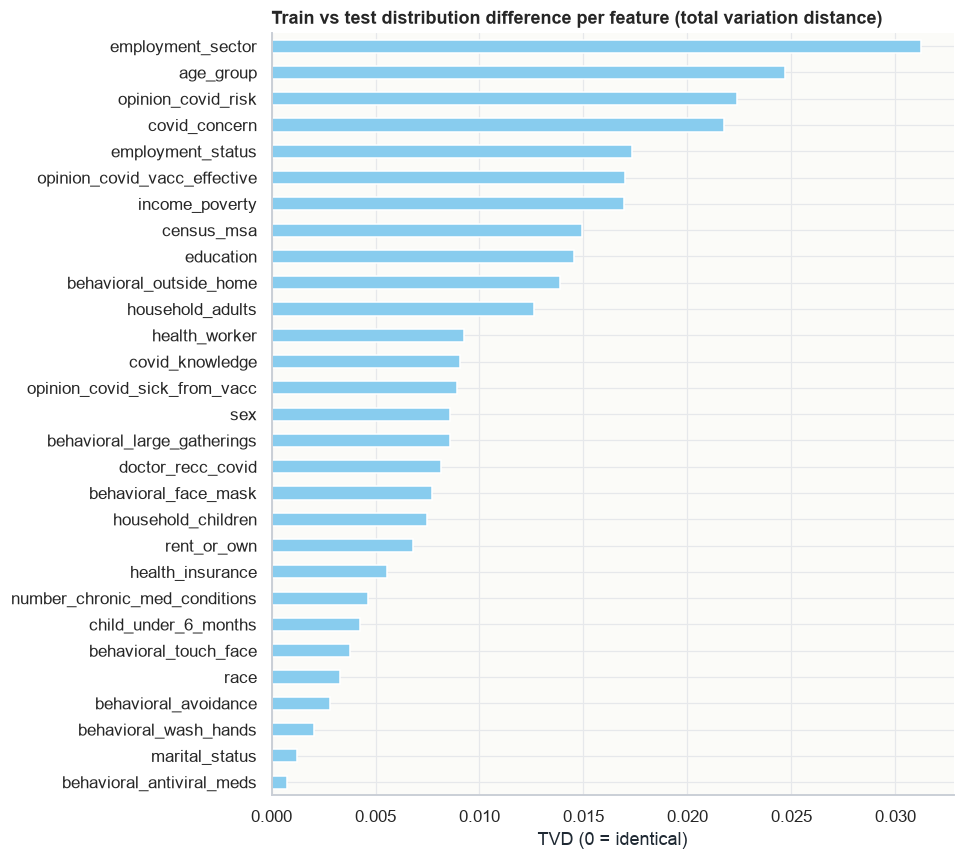

Largest per-feature TVD: 0.031 (employment_sector)
Adversarial validation AUC: 0.503 ± 0.007  (0.5 = train and test indistinguishable)


In [ ]:
from sklearn.model_selection import cross_val_score
tvd = pd.Series({c: 0.5 * train[c].astype(str).value_counts(normalize=True)
                       .sub(test[c].astype(str).value_counts(normalize=True), fill_value=0).abs().sum() for c in FEATS}).sort_values()
ax = tvd.plot(kind='barh', figsize=(8, 9), color='#88ccee')
ax.set_title('Train vs test distribution difference per feature (total variation distance)'); ax.set_xlabel('TVD (0 = identical)'); plt.show()

both = pd.concat([train[FEATS], test[FEATS]], ignore_index=True)
both = both.apply(lambda s: s.astype('category').cat.codes if not pd.api.types.is_numeric_dtype(s) else s)
is_test = np.r_[np.zeros(len(train)), np.ones(len(test))]
adv_auc = cross_val_score(LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, random_state=SEED, verbose=-1),
                          both, is_test, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring='roc_auc')
print(f'Largest per-feature TVD: {tvd.max():.3f} ({tvd.idxmax()})')
print(f'Adversarial validation AUC: {adv_auc.mean():.3f} ± {adv_auc.std():.3f}  (0.5 = train and test indistinguishable)')

### 2.14 How opinions differ between people who vaccinated and those who did not
A **diverging bar chart** (the standard way to show survey scales): negative answers extend left of zero, positive ones right, "Don't know" is split across the centre line. The further the two bars of a panel sit apart, the more that opinion separates the two groups.

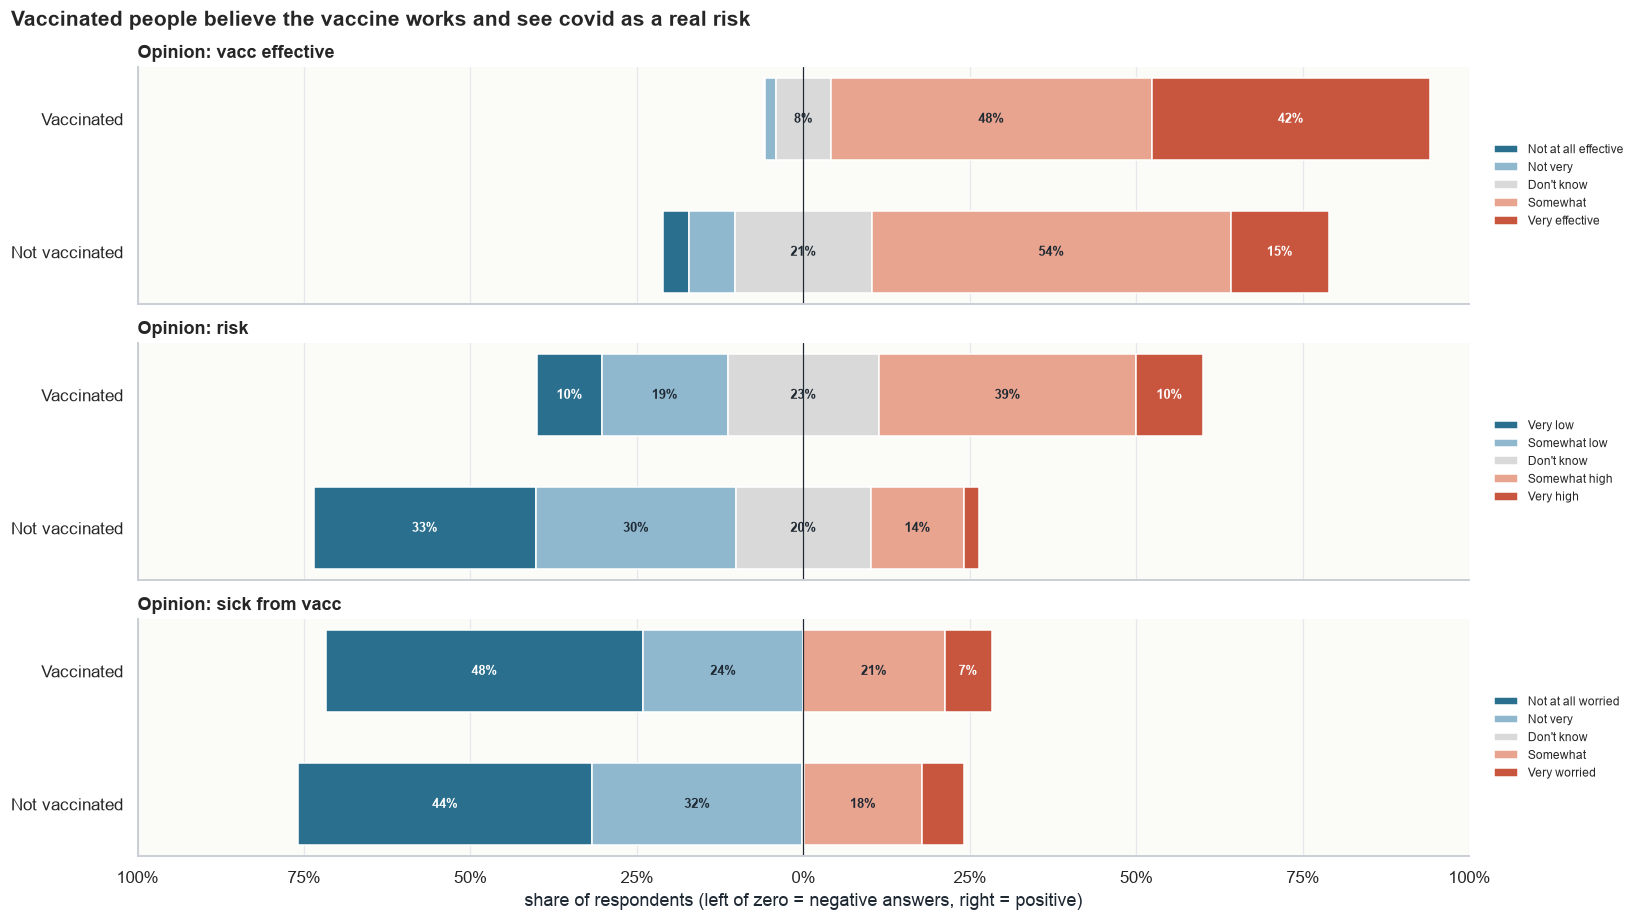

opinion_covid_vacc_effective: answered 4-5 -> vaccinated 90% vs not vaccinated 69%
opinion_covid_risk: answered 4-5 -> vaccinated 49% vs not vaccinated 16%
opinion_covid_sick_from_vacc: answered 4-5 -> vaccinated 28% vs not vaccinated 24%
Note: worry about getting sick from the vaccine is almost the same in both groups, so it is a weak signal on its own.


In [ ]:
LIKERT = {
    'opinion_covid_vacc_effective': ['Not at all effective', 'Not very', "Don't know", 'Somewhat', 'Very effective'],
    'opinion_covid_risk': ['Very low', 'Somewhat low', "Don't know", 'Somewhat high', 'Very high'],
    'opinion_covid_sick_from_vacc': ['Not at all worried', 'Not very', "Don't know", 'Somewhat', 'Very worried']}
likert_colours = ['#2B6F8E', '#8FB8CF', '#D9D9D9', '#E8A48F', '#C8553D']

fig, axes = plt.subplots(3, 1, figsize=(15, 8.5), sharex=True)
for ax, (col, labels) in zip(axes, LIKERT.items()):
    for row, (grp, name) in enumerate([(1, 'Vaccinated'), (0, 'Not vaccinated')]):
        shares = train.loc[train[TARGET] == grp, col].dropna().value_counts(normalize=True).reindex([1, 2, 3, 4, 5], fill_value=0).to_numpy()
        left = -(shares[0] + shares[1] + shares[2] / 2)          # centre "Don't know" on zero
        for k in range(5):
            ax.barh(row, shares[k], left=left, color=likert_colours[k], edgecolor='white', height=0.62,
                    label=labels[k] if row == 0 else None)
            if shares[k] > 0.07:
                ax.text(left + shares[k] / 2, row, f'{shares[k]:.0%}', ha='center', va='center', fontsize=8.5,
                        color='white' if k in (0, 4) else PAL['ink'], fontweight='bold')
            left += shares[k]
    ax.axvline(0, color=PAL['ink'], lw=0.8)
    ax.set_yticks([0, 1], ['Vaccinated', 'Not vaccinated']); ax.set_xlim(-1, 1); ax.grid(axis='y', visible=False)
    ax.set_title(col.replace('opinion_covid_', 'Opinion: ').replace('_', ' '))
    ax.invert_yaxis()                                         # 'Vaccinated' on top
    ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=8)
axes[-1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{abs(v):.0%}'))
axes[-1].set_xlabel('share of respondents (left of zero = negative answers, right = positive)')
fig.suptitle('Vaccinated people believe the vaccine works and see covid as a real risk', x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()
for col in LIKERT:
    pos = train.groupby(TARGET)[col].apply(lambda s: (s.dropna() >= 4).mean())
    print(f"{col}: answered 4-5 -> vaccinated {pos[1]:.0%} vs not vaccinated {pos[0]:.0%}")
print("Note: worry about getting sick from the vaccine is almost the same in both groups, so it is a weak signal on its own.")

### 2.15 The two strongest signals together: doctor's advice × perceived risk
Each bubble is a group of respondents: its **position** gives the doctor's recommendation and perceived risk, its **size** the number of people, its **colour and label** their vaccination rate.

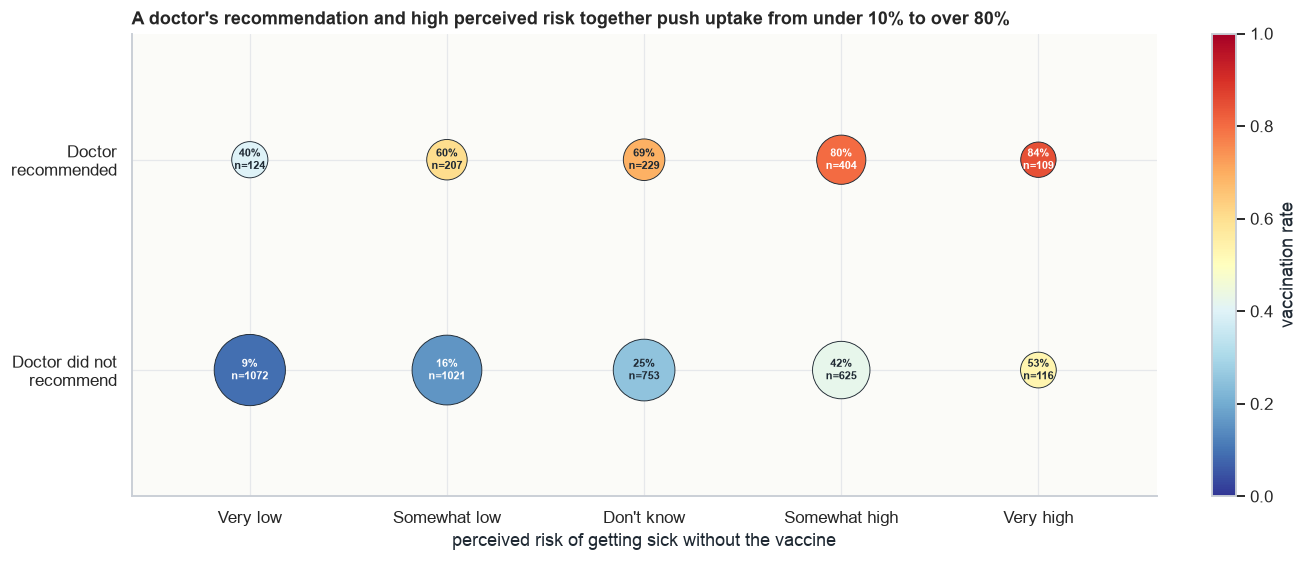

uptake: no recommendation + very low risk = 9% | recommendation + very high risk = 84%


In [ ]:
g = train.groupby(['opinion_covid_risk', 'doctor_recc_covid'])[TARGET].agg(rate='mean', n='size').reset_index()
fig, ax = plt.subplots(figsize=(12, 5.2))
sc = ax.scatter(g['opinion_covid_risk'], g['doctor_recc_covid'], s=350 + g['n'] * 1.7, c=g['rate'], cmap='RdYlBu_r',
                vmin=0, vmax=1, edgecolor=PAL['ink'], linewidth=0.6, zorder=3)       # minimum size keeps small groups readable
for _, r in g.iterrows():
    ax.text(r['opinion_covid_risk'], r['doctor_recc_covid'], f"{r['rate']:.0%}\nn={int(r['n'])}", ha='center', va='center',
            fontsize=7.5, color='white' if abs(r['rate'] - 0.5) > 0.25 else PAL['ink'], fontweight='bold', zorder=4)
ax.set_xticks([1, 2, 3, 4, 5], LIKERT['opinion_covid_risk']); ax.set_yticks([0, 1], ['Doctor did not\nrecommend', 'Doctor\nrecommended'])
ax.set_ylim(-0.6, 1.6); ax.set_xlim(0.4, 5.6); ax.set_xlabel('perceived risk of getting sick without the vaccine')
fig.colorbar(sc, ax=ax, label='vaccination rate', fraction=0.03)
ax.set_title("A doctor's recommendation and high perceived risk together push uptake from under 10% to over 80%")
plt.tight_layout(); plt.show()
lo = g.loc[(g.doctor_recc_covid == 0) & (g.opinion_covid_risk == 1), 'rate'].iloc[0]
hi = g.loc[(g.doctor_recc_covid == 1) & (g.opinion_covid_risk == 5), 'rate'].iloc[0]
print(f'uptake: no recommendation + very low risk = {lo:.0%} | recommendation + very high risk = {hi:.0%}')

### 2.16 Missing-data map
Every row is a respondent, every column a feature with gaps (dark = missing). Rows are sorted by vaccination status (strip on the right) and then by how many questions they skipped, so blocks of questions skipped together and any link with the target become visible at a glance.

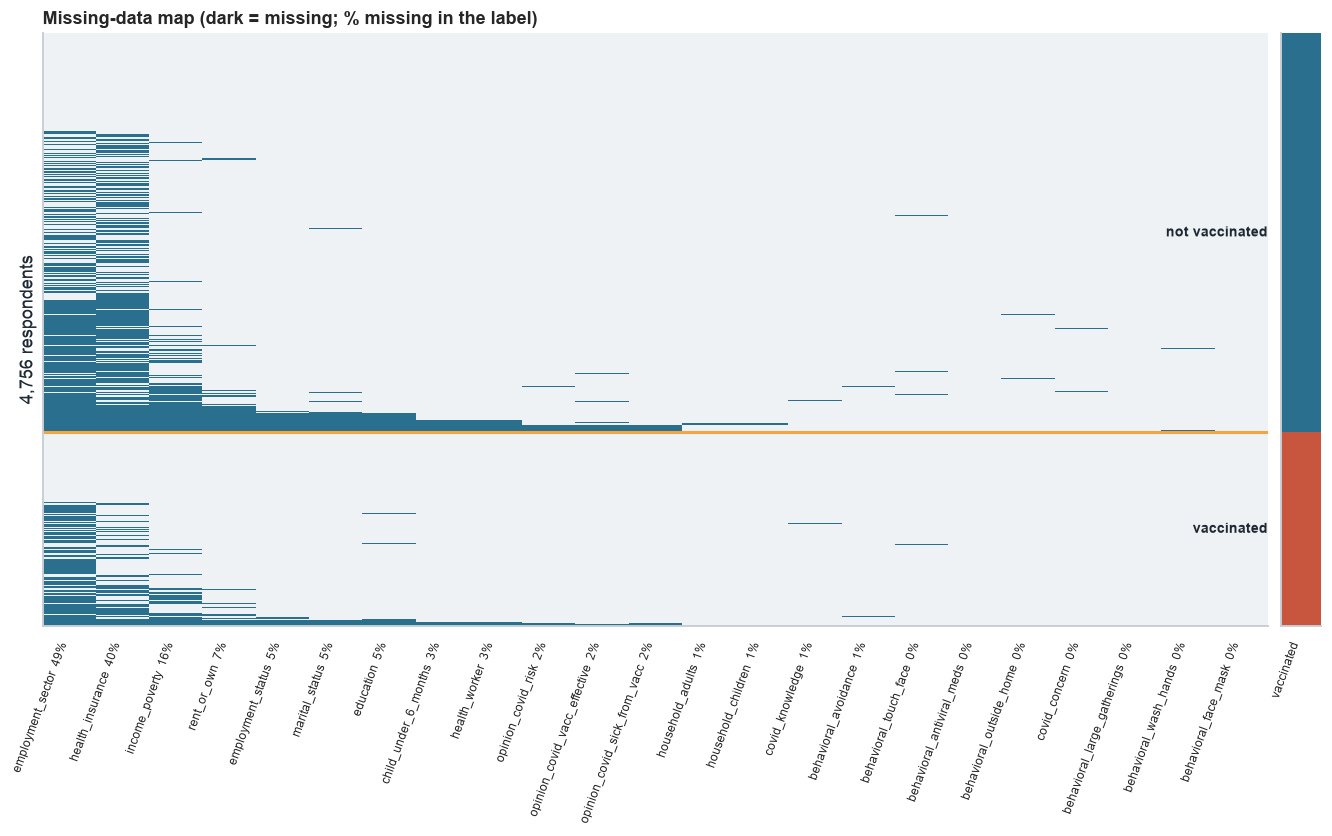

In [ ]:
gap_cols = [c for c in FEATS if train[c].isna().any()]
gap_cols = sorted(gap_cols, key=lambda c: -train[c].isna().mean())
miss = train[gap_cols].isna()
row_order = train.assign(_gaps=miss.sum(axis=1)).sort_values([TARGET, '_gaps']).index

fig, (ax, ax_t) = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [30, 1], 'wspace': 0.02})
ax.imshow(miss.loc[row_order].to_numpy(), aspect='auto', interpolation='nearest', cmap=ListedColormap(['#EEF2F5', '#2B6F8E']))
ax.set_xticks(range(len(gap_cols)), [f"{c}  {train[c].isna().mean():.0%}" for c in gap_cols], rotation=70, ha='right', fontsize=8)
ax.set_yticks([]); ax.grid(False); ax.set_ylabel(f'{len(train):,} respondents')
ax.set_title('Missing-data map (dark = missing; % missing in the label)')
ax_t.imshow(train.loc[row_order, [TARGET]].to_numpy(), aspect='auto', interpolation='nearest', cmap=ListedColormap([PAL['no'], PAL['yes']]))
ax_t.set_xticks([0], ['vaccinated'], rotation=70, ha='right', fontsize=8); ax_t.set_yticks([]); ax_t.grid(False)
split = (train[TARGET] == 0).sum()
ax.axhline(split - 0.5, color=PAL['accent'], lw=2)
ax.text(len(gap_cols) - 0.5, split / 2, 'not vaccinated', ha='right', va='center', color=PAL['ink'], fontsize=9, fontweight='bold')
ax.text(len(gap_cols) - 0.5, split + (len(train) - split) / 2, 'vaccinated', ha='right', va='center', color=PAL['ink'], fontsize=9, fontweight='bold')
plt.show()

### 2.17 Feature strength at a glance
Mutual information with vaccination for all 29 features, coloured by theme. Filled dots are significant (chi-square p < 0.05); hollow dots are not, so those features are unlikely to help on their own.

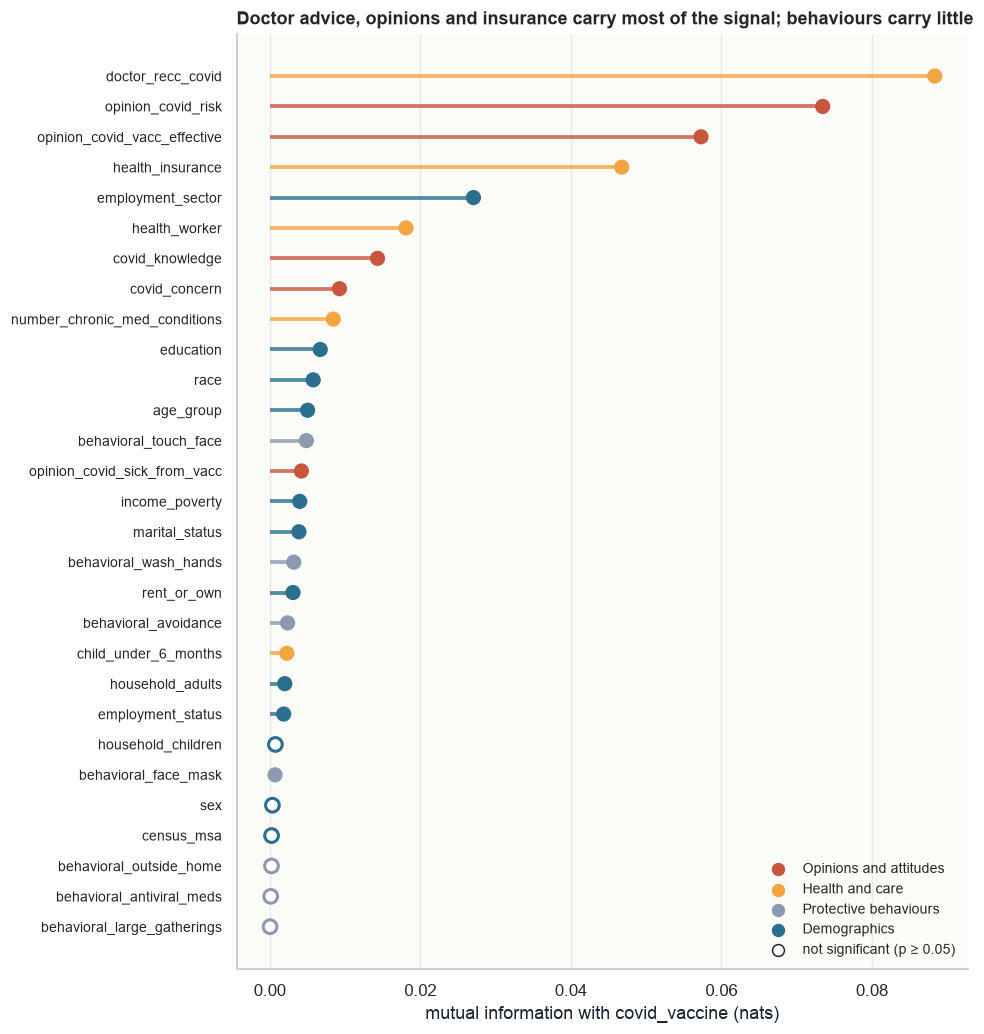

{'Health and care': 0.164, 'Opinions and attitudes': 0.159, 'Demographics': 0.061, 'Protective behaviours': 0.012}


In [ ]:
def theme_of(c):
    if c.startswith('opinion') or c in ('covid_concern', 'covid_knowledge'): return 'Opinions and attitudes'
    if c.startswith('behavioral'): return 'Protective behaviours'
    if c in ('doctor_recc_covid', 'health_insurance', 'health_worker', 'child_under_6_months', 'number_chronic_med_conditions'): return 'Health and care'
    return 'Demographics'
THEME_COL = {'Opinions and attitudes': PAL['yes'], 'Health and care': PAL['accent'], 'Protective behaviours': PAL['neutral'], 'Demographics': PAL['no']}

s = strength.sort_values('mutual information')
colours = [THEME_COL[theme_of(c)] for c in s.index]
sig = s['chi2 p-value'] < 0.05
fig, ax = plt.subplots(figsize=(9, 9.5))
ax.hlines(range(len(s)), 0, s['mutual information'], color=colours, lw=2.5, alpha=0.8)
ax.scatter(s['mutual information'][sig], np.arange(len(s))[sig], s=80, c=np.array(colours)[sig], zorder=3)
ax.scatter(s['mutual information'][~sig], np.arange(len(s))[~sig], s=80, facecolors='white', edgecolors=np.array(colours)[~sig], lw=2, zorder=3)
ax.set_yticks(range(len(s)), s.index, fontsize=9); ax.grid(axis='y', visible=False)
for name, col in THEME_COL.items():
    ax.scatter([], [], color=col, s=60, label=name)
ax.scatter([], [], facecolors='white', edgecolors=PAL['ink'], s=60, label='not significant (p ≥ 0.05)')
ax.legend(loc='lower right', fontsize=9); ax.set_xlabel('mutual information with covid_vaccine (nats)')
ax.set_title('Doctor advice, opinions and insurance carry most of the signal; behaviours carry little')
plt.tight_layout(); plt.show()
print(strength.assign(theme=[theme_of(c) for c in strength.index]).groupby('theme')['mutual information'].sum().sort_values(ascending=False).round(3).to_dict())

### 2.18 Does the effect of an opinion depend on age?
Vaccination rate at each answer of the three opinion scales, one line per age group, with 95% confidence bands. Parallel lines mean the opinion works the same way at every age; lines that fan out point to an interaction, which tree models can capture.

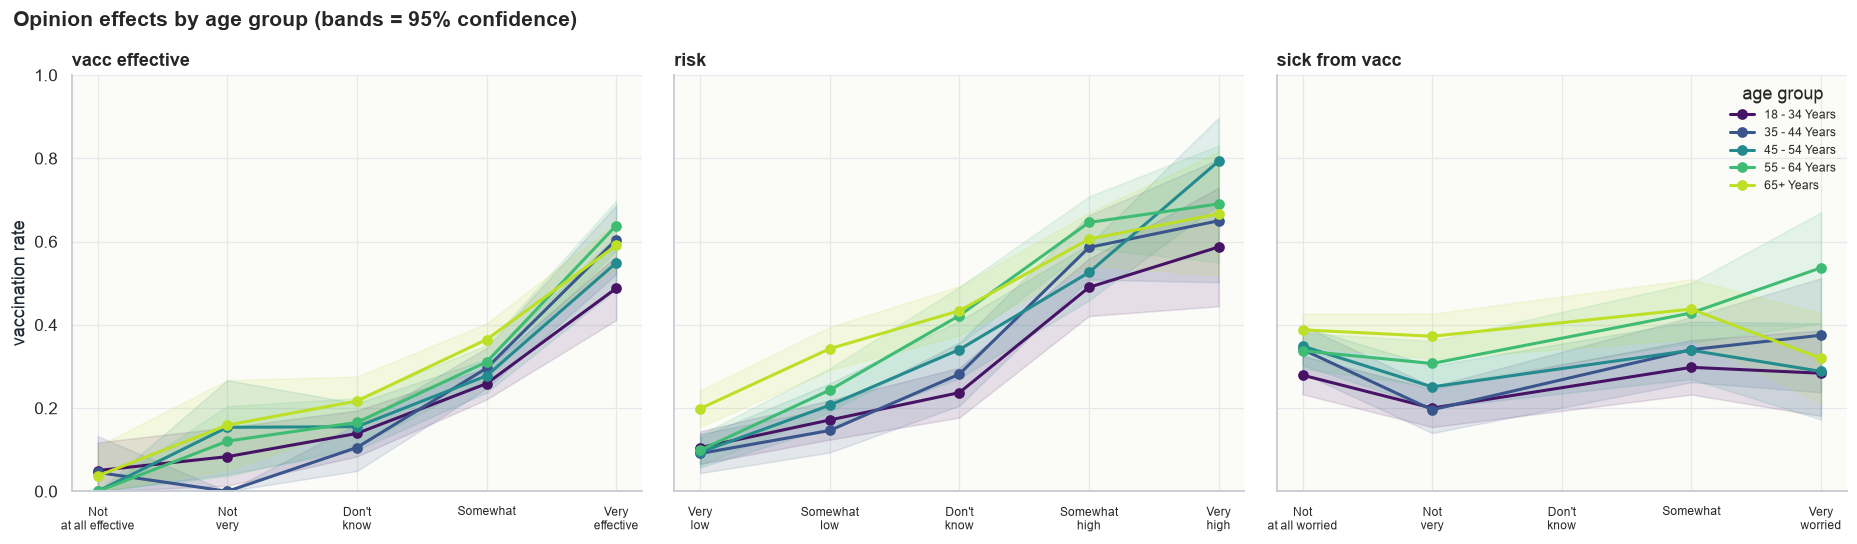

In [ ]:
age_colours = dict(zip(P_HOSP_AGE if 'P_HOSP_AGE' in globals() else sorted(train['age_group'].unique()),
                       plt.cm.viridis(np.linspace(0.05, 0.9, 5))))
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, (col, labels) in zip(axes, LIKERT.items()):
    for age, part in train.groupby('age_group'):
        t = part.groupby(col)[TARGET].agg(['mean', 'size'])
        t = t[t['size'] >= 15]                                      # skip tiny cells, their rates are unreliable
        se = np.sqrt(t['mean'] * (1 - t['mean']) / t['size'])
        ax.plot(t.index, t['mean'], marker='o', lw=2, color=age_colours[age], label=age)
        ax.fill_between(t.index, (t['mean'] - 1.96 * se).clip(0, 1), (t['mean'] + 1.96 * se).clip(0, 1), color=age_colours[age], alpha=0.12)
    ax.set_xticks([1, 2, 3, 4, 5], [l.replace(' ', '\n', 1) for l in labels], fontsize=8)
    ax.set_title(col.replace('opinion_covid_', '').replace('_', ' '))
axes[0].set_ylabel('vaccination rate'); axes[0].set_ylim(0, 1)
axes[-1].legend(title='age group', loc='upper right', fontsize=8)
fig.suptitle('Opinion effects by age group (bands = 95% confidence)', x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### 2.19 EDA summary: findings → decisions
Every key finding and the modelling decision it led to (numbers computed above).

In [ ]:
sig_missing = miss_tbl.loc[miss_tbl['chi2 p-value'] < 0.01, 'column'].tolist()
findings = pd.DataFrame([
    ('Target is imbalanced', f'{rate:.1%} vaccinated',
     'Stratified CV; score with the town cost and decide with probabilities + personal thresholds, not accuracy'),
    ('Heavy missingness', f"employment_sector {train['employment_sector'].isna().mean():.0%}, health_insurance {train['health_insurance'].isna().mean():.0%}",
     'Keep missing as information: missing-value indicators (linear) and native NaN handling (trees)'),
    ('Missingness is linked to the target', f'{len(sig_missing)} columns with p < 0.01, e.g. {", ".join(sig_missing[:3])}',
     'Do not simply median-impute; compared in section 5.1'),
    ('Invalid codes', 'opinion_covid_vacc_effective / opinion_covid_risk contain 0 (sheet range 1-5), about 2% of rows',
     'Treated as missing (section 1.1)'),
    ('Strongest single predictors', ', '.join(strength.index[:4]),
     'Engineered doc_x_risk (doctor recommendation × perceived risk); its value is tested in section 5.1'),
    ('Behaviour flags are mostly weak and separate', f"{(pairs.abs() > 0.4).sum()} pair with |Spearman| > 0.4; several flags not significant (2.11)",
     'Engineered behavioral_count to combine weak signals; tested in section 5.1'),
    ('High-cardinality categorical', f"employment_sector has {train['employment_sector'].nunique()} levels",
     'One-hot for linear models, ordinal codes for trees, all inside pipelines (no leakage)'),
    ('Age and chronic conditions raise vaccination', f"{train.groupby('age_group')[TARGET].mean().min():.0%} (youngest) to {train.groupby('age_group')[TARGET].mean().max():.0%} (65+)",
     'They also raise hospitalisation risk, so they enter the metric twice: personal thresholds (section 3.6)'),
    ('No train/test shift', f'adversarial AUC {adv_auc.mean():.2f}, max TVD {tvd.max():.3f}',
     'Cross-validated town cost is a fair estimate of the hidden-test cost'),
], columns=['Finding', 'Evidence', 'Decision'])
pd.set_option('display.max_colwidth', None)
display(findings.style.hide(axis='index'))

Finding,Evidence,Decision
Target is imbalanced,32.7% vaccinated,"Stratified CV; score with the town cost and decide with probabilities + personal thresholds, not accuracy"
Heavy missingness,"employment_sector 49%, health_insurance 40%",Keep missing as information: missing-value indicators (linear) and native NaN handling (trees)
Missingness is linked to the target,"3 columns with p < 0.01, e.g. health_insurance, marital_status, education",Do not simply median-impute; compared in section 5.1
Invalid codes,"opinion_covid_vacc_effective / opinion_covid_risk contain 0 (sheet range 1-5), about 2% of rows",Treated as missing (section 1.1)
Strongest single predictors,"doctor_recc_covid, opinion_covid_risk, opinion_covid_vacc_effective, health_insurance",Engineered doc_x_risk (doctor recommendation × perceived risk); its value is tested in section 5.1
Behaviour flags are mostly weak and separate,1 pair with |Spearman| > 0.4; several flags not significant (2.11),Engineered behavioral_count to combine weak signals; tested in section 5.1
High-cardinality categorical,employment_sector has 21 levels,"One-hot for linear models, ordinal codes for trees, all inside pipelines (no leakage)"
Age and chronic conditions raise vaccination,26% (youngest) to 39% (65+),"They also raise hospitalisation risk, so they enter the metric twice: personal thresholds (section 3.6)"
No train/test shift,"adversarial AUC 0.50, max TVD 0.031",Cross-validated town cost is a fair estimate of the hidden-test cost


## 3. The task metric: total town cost

### 3.1 Cost of each outcome
With V = $1,500 (vaccine), H = $41,000 (hospitalisation), and p_u / p_v the hospitalisation probability unvaccinated / vaccinated:

| We send a vaccine? | Person wants it? | Town pays |
|---|---|---|
| yes | yes | V + p_v·H (vaccinated) |
| yes | no | V (wasted) + p_u·H |
| no | yes | V (cash) + p_u·H (stays unvaccinated) |
| no | no | p_u·H |

### 3.2 Optimal decision
If our model says a person accepts with probability q, sending costs `V + q·p_v·H + (1-q)·p_u·H`, not sending costs `q·V + p_u·H`.
Sending is cheaper when

**q > V / (V + (p_u − p_v)·H)**

so every person has their **own threshold**: high-risk people (old, chronic conditions) should get a vaccine even at a modest acceptance probability, low-risk young people only when we are quite sure they will use it.
A default 0.5 threshold ignores this and costs the town money (shown in section 9).

### 3.3 Hospitalisation probabilities (research with generative AI)
The sheet asks us to estimate these with generative AI, asking several AIs / several people. Each AI's answer is recorded below and the code uses the average. All three are Claude models; adding a row from a different provider (e.g. Gemini or ChatGPT, asked by another team member) would make the "different AIs" requirement stronger.

| Source | 18-34 | 35-44 | 45-54 | 55-64 | 65+ | Vaccine effectiveness | Per chronic condition |
|---|---|---|---|---|---|---|---|
| Claude Sonnet 5.5 (asked separately, same prompt) | 0.010 | 0.018 | 0.030 | 0.055 | 0.140 | 0.80 | ×1.8 |
| Claude Haiku 5.5 (asked separately, same prompt) | 0.006 | 0.012 | 0.025 | 0.050 | 0.120 | 0.85 | ×1.6 |
| Claude Fable 5.2 (asked separately, same prompt) | 0.012 | 0.025 | 0.045 | 0.080 | 0.200 | 0.85 | ×1.5 |
| **Used (average of the 3)** | 0.0093 | 0.0183 | 0.0333 | 0.0617 | 0.1533 | 0.833 | ×1.633 |

All three assumed pre-Omicron (wild-type to Delta) severity in an unvaccinated, immunologically naive population, citing Verity et al. 2020, Salje et al. 2020, CDC planning scenarios / COVID-NET, OpenSAFELY / Kompaniyets et al. 2021 (comorbidities) and Tenforde / Thompson et al. 2021 (vaccine effectiveness). Two of the three advised **capping** the probability because ×m per condition can exceed 1 for elderly people with many conditions, so we cap at 0.9. Full answers: `docs/ai_hospitalisation_estimates.md`. Section 9.3 checks how sensitive our ranking is to these numbers.

> 👤 **Section owner:** Iqra Fazal  
> 📌 **Section rules:** Do **not** change V = $1,500 or H = $41,000 (given on the sheet). Record every AI answer as a new row in the 3.3 table before changing the averages. Keep the hand-check `assert` passing.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `Metric:` and ends with your name.

In [ ]:
# ---- Given on the dataset sheet ----
V = 1_500.0      # $ per covid vaccine
H = 41_000.0     # $ per covid hospitalisation

# ---- Generative-AI research: average of 3 AIs (table in 3.3) ----
P_HOSP_AGE = {'18 - 34 Years': 0.0093, '35 - 44 Years': 0.0183, '45 - 54 Years': 0.0333, '55 - 64 Years': 0.0617, '65+ Years': 0.1533}   # P(hospitalised | infected, unvaccinated): mean of 3 AIs
VE = 0.833             # vaccine effectiveness against hospitalisation: mean of 3 AIs
CHRONIC_MULT = 1.633   # risk multiplier per chronic condition (compounding): mean of 3 AIs
P_CAP = 0.9              # cap on hospitalisation probability (advised by 2 of the 3 AIs)

def hosp_probs(df, p_age=P_HOSP_AGE, ve=VE, chronic_mult=CHRONIC_MULT):
    """Hospitalisation probability for each person: (unvaccinated, vaccinated)."""
    p_u = df['age_group'].map(p_age).fillna(np.mean(list(p_age.values()))).to_numpy(float)
    p_u = np.clip(p_u * chronic_mult ** df['number_chronic_med_conditions'].fillna(0).to_numpy(float), 0, P_CAP)
    return p_u, p_u * (1 - ve)

def town_cost(y_true, sent, p_u, p_v, V=V, H=H):
    """Total $ spent by the town (lower is better)."""
    y_true, sent = np.asarray(y_true).astype(int), np.asarray(sent).astype(int)
    vaccine_cost = V * ((sent == 1) | (y_true == 1))          # posted, or paid in cash because they wanted one
    hosp_cost = H * np.where((sent == 1) & (y_true == 1), p_v, p_u)   # only accepted vaccines protect
    return float(np.sum(vaccine_cost + hosp_cost))

def personal_threshold(p_u, p_v, V=V, H=H):
    return V / (V + (p_u - p_v) * H)

def decide(q, p_u, p_v, V=V, H=H):
    """1 = post a vaccine, when the expected saving beats the expected waste."""
    return (np.asarray(q) > personal_threshold(p_u, p_v, V, H)).astype(int)

# Hand check on 4 people aged 18-34 with no chronic condition: TP, FN, FP, TN
_df = pd.DataFrame({'age_group': ['18 - 34 Years'] * 4, 'number_chronic_med_conditions': [0] * 4})
_pu, _pv = hosp_probs(_df)
_expected = (V + _pv[0]*H) + (V + _pu[0]*H) + (V + _pu[0]*H) + (_pu[0]*H)
assert np.isclose(town_cost([1, 1, 0, 0], [1, 0, 1, 0], _pu, _pv), _expected)
print('metric hand check passed:', _expected)

metric hand check passed: 5707.5771


### 3.4 Personal thresholds
The acceptance probability needed before posting a vaccine falls sharply with age and chronic conditions.

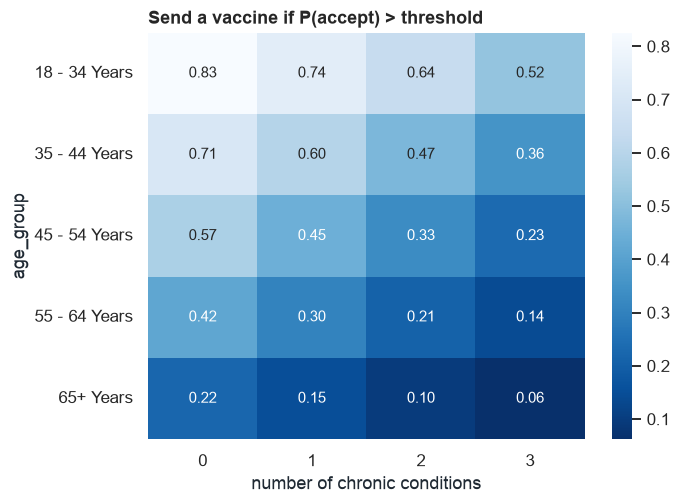

In [ ]:
grid = pd.DataFrame([(a, c) for a in P_HOSP_AGE for c in range(4)], columns=['age_group', 'number_chronic_med_conditions'])
grid['threshold'] = personal_threshold(*hosp_probs(grid))
sns.heatmap(grid.pivot(index='age_group', columns='number_chronic_med_conditions', values='threshold'),
            annot=True, fmt='.2f', cmap='Blues_r')
plt.title('Send a vaccine if P(accept) > threshold'); plt.xlabel('number of chronic conditions'); plt.show()

### 3.5 Baselines on the training data
Any model must beat the trivial policies. *Perfect knowledge* is the lowest cost achievable.

In [ ]:
PU, PV = hosp_probs(train)
n = len(train)
baselines = {'Send nobody': np.zeros(n), 'Send everybody': np.ones(n), 'Perfect knowledge': y}
base_tbl = pd.DataFrame({k: {'total $': town_cost(y, s, PU, PV), '$ per resident': town_cost(y, s, PU, PV) / n}
                         for k, s in baselines.items()}).T
base_tbl.style.format('{:,.0f}')

,total $,$ per resident
Send nobody,"19,070,632","4,010"
Send everybody,"18,551,289","3,901"
Perfect knowledge,"13,748,289","2,891"


### 3.6 EDA through the cost lens
Who are the expensive residents? We combine the hospitalisation model with the data: risk per person, the acceptance probability needed before posting a vaccine (threshold), and the observed acceptance rate in each age × chronic-conditions segment.

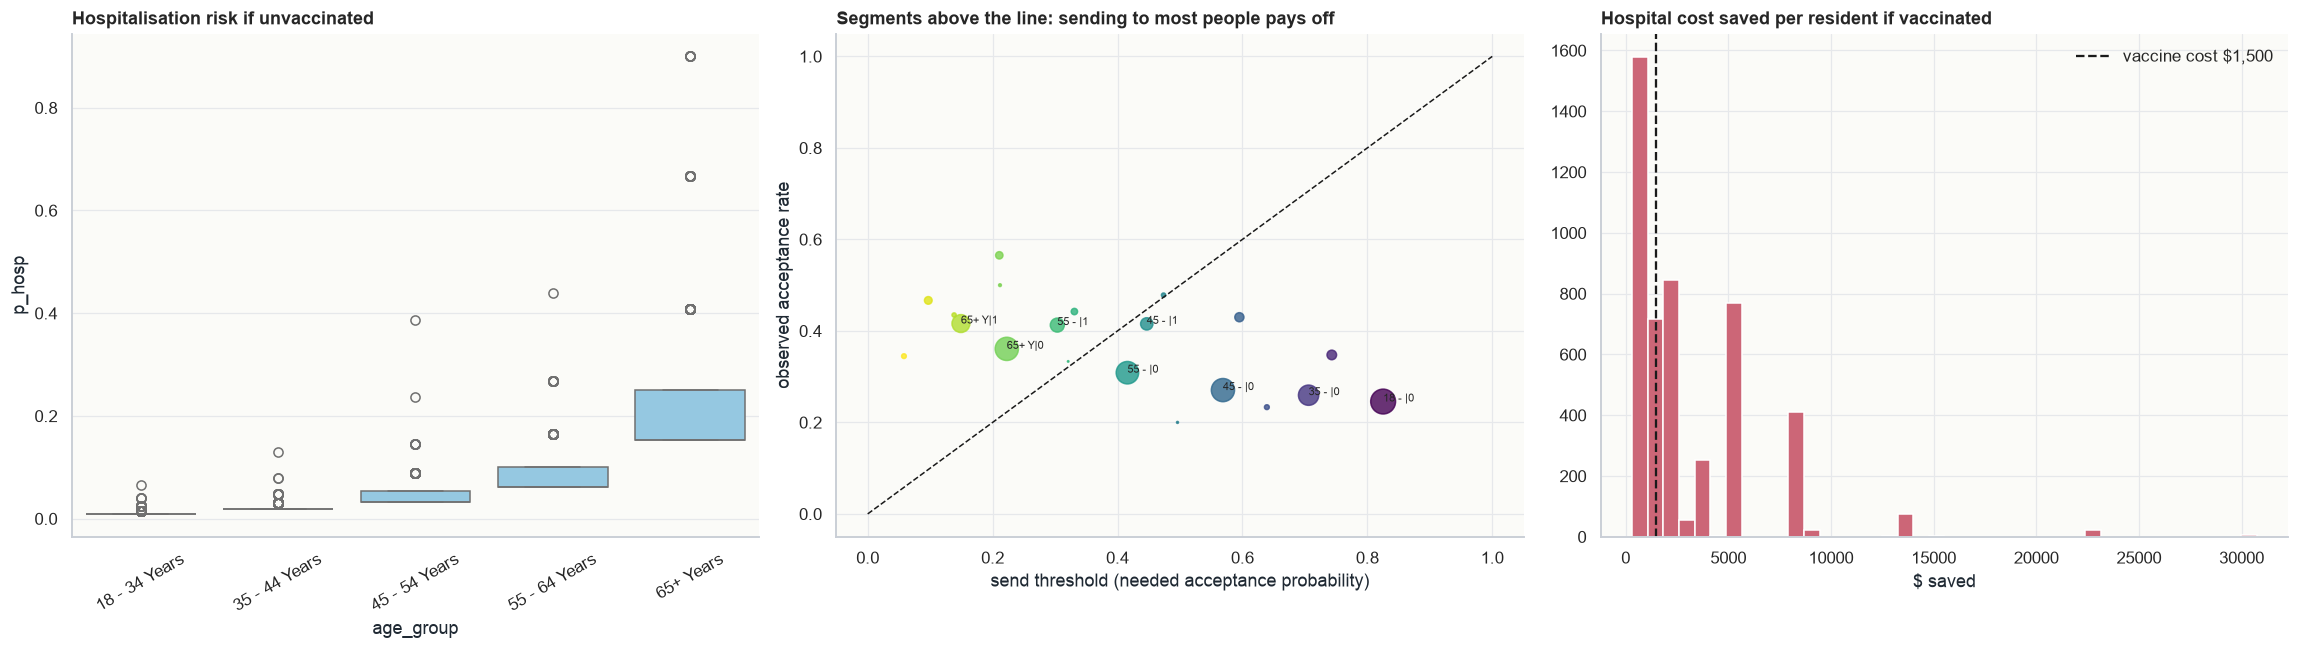

11 of 20 age×chronic segments (34% of residents) have average acceptance above their threshold.
Share of residents for whom one vaccine saves more in expected hospital costs than it costs: 52.2%


,acceptance rate,p_hosp,threshold,stake
age_group,,,,
18 - 34 Years,0.258,0.011,0.807,$366
35 - 44 Years,0.295,0.022,0.678,$737
45 - 54 Years,0.312,0.042,0.527,"$1,442"
55 - 64 Years,0.356,0.084,0.367,"$2,860"
65+ Years,0.386,0.216,0.186,"$7,373"


In [ ]:
seg = train.assign(p_hosp=PU, threshold=personal_threshold(PU, PV), stake=(PU - PV) * H,
                   chronic=train['number_chronic_med_conditions'].clip(upper=3).astype(int).astype(str).replace({'3': '3+'}))
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
sns.boxplot(data=seg, x='age_group', y='p_hosp', order=list(P_HOSP_AGE), ax=axes[0], color='#88ccee')
axes[0].set_title('Hospitalisation risk if unvaccinated'); axes[0].tick_params(axis='x', rotation=30)

cell = seg.groupby(['age_group', 'chronic']).agg(acceptance=(TARGET, 'mean'), threshold=('threshold', 'mean'), size=(TARGET, 'size')).reset_index()
sc = axes[1].scatter(cell['threshold'], cell['acceptance'], s=cell['size'] / 3, c=cell['threshold'], cmap='viridis_r', alpha=0.8)
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
for _, r in cell[cell['size'] > 150].iterrows():
    axes[1].annotate(f"{r['age_group'][:5]}|{r['chronic']}", (r['threshold'], r['acceptance']), fontsize=7)
axes[1].set_xlabel('send threshold (needed acceptance probability)'); axes[1].set_ylabel('observed acceptance rate')
axes[1].set_title('Segments above the line: sending to most people pays off')

axes[2].hist(seg['stake'], bins=40, color='#cc6677')
axes[2].axvline(V, c='k', ls='--', label=f'vaccine cost ${V:,.0f}')
axes[2].set_title('Hospital cost saved per resident if vaccinated'); axes[2].set_xlabel('$ saved'); axes[2].legend()
plt.tight_layout(); plt.show()

above = cell[cell['acceptance'] > cell['threshold']]
print(f"{len(above)} of {len(cell)} age×chronic segments ({above['size'].sum() / len(train):.0%} of residents) have average acceptance above their threshold.")
print(f"Share of residents for whom one vaccine saves more in expected hospital costs than it costs: {(seg['stake'] > V).mean():.1%}")
display(seg.groupby('age_group')[[TARGET, 'p_hosp', 'threshold', 'stake']].mean()
           .rename(columns={TARGET: 'acceptance rate'}).style.format('{:.3f}', subset=['acceptance rate', 'p_hosp', 'threshold']).format('${:,.0f}', subset=['stake']))

## 4. Pre-processing
Two variants are compared:

* **A (linear models):** median imputation + missing-value indicators + standard scaling for numeric columns, one-hot encoding (missing = own category) for categorical columns.
* **B (tree models):** ordinal encoding of categoricals, NaN kept as-is (HistGradientBoosting and LightGBM handle it natively; for Random Forest we impute with -1).

Engineered features (both variants): `behavioral_count` (number of precautions taken) and `doc_x_risk` (doctor recommendation × perceived risk), whose value is measured in section 5.1 rather than assumed.

> 👤 **Section owner:** Aqsa Iqbal  
> 📌 **Section rules:** All imputation/encoding must live **inside a `Pipeline` / `ColumnTransformer`** so it is fitted only on training folds (no leakage). Compare every new option with `evaluate()` (town cost), as in 5.1.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `Pre-processing:` and ends with your name.

In [ ]:
CAT = ['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status',
       'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']
BEH = [c for c in train.columns if c.startswith('behavioral_')]

def add_features(df):
    df = df.copy()
    df['behavioral_count'] = df[BEH].sum(axis=1)
    df['doc_x_risk'] = df['doctor_recc_covid'].fillna(0) * df['opinion_covid_risk'].fillna(0)
    return df

X = add_features(train.drop(columns=[TARGET, ID]))
X_test = add_features(test.drop(columns=[ID]))
NUM = [c for c in X.columns if c not in CAT]
CAT_IDX = list(range(len(CAT)))        # categoricals come first after the ordinal transformer

pre_A = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('sc', StandardScaler())]), NUM),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='missing')),
                      ('ohe', OneHotEncoder(handle_unknown='ignore'))]), CAT)])
pre_B = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1), CAT),
    ('num', 'passthrough', NUM)])
pre_B_imputed = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1), CAT),
    ('num', SimpleImputer(strategy='constant', fill_value=-1), NUM)])
print(f'{len(NUM)} numeric + {len(CAT)} categorical features')

21 numeric + 10 categorical features


## 5. Models scored with repeated cross-validation
Every model is evaluated with **5-fold stratified CV repeated 3 times (15 folds)**. In each fold we fit on 4/5 of the data, predict acceptance probabilities on the held-out 1/5, apply the personal-threshold rule and compute the **town cost per resident**.
The spread over the 15 folds (std) tells us how large random variation is, so we only trust differences between models that are bigger than this noise.

> 👤 **Section owner:** Kodi Chinthala Vaishnavi  
> 📌 **Section rules:** Add each new model to the `models` dict and score it **only with `evaluate()`** (same 15 folds, town cost mean ± std). Do not rank by accuracy, F1 or AUC alone. Keep `random_state=SEED`.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `Models:` and ends with your name.

In [ ]:
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

def evaluate(pipe, X=X, y=y, cv=CV):
    """Fold-wise town cost per resident (personal thresholds) and at a 0.5 cut-off, plus AUC and log loss."""
    rows, oof, cnt = [], np.zeros(len(y)), np.zeros(len(y))
    for tr, va in cv.split(X, y):
        m = clone(pipe).fit(X.iloc[tr], y[tr])
        q = m.predict_proba(X.iloc[va])[:, 1]
        pu, pv = PU[va], PV[va]
        rows.append({'cost': town_cost(y[va], decide(q, pu, pv), pu, pv) / len(va),
                     'cost_at_0.5': town_cost(y[va], q >= 0.5, pu, pv) / len(va),
                     'auc': roc_auc_score(y[va], q), 'logloss': log_loss(y[va], q)})
        oof[va] += q; cnt[va] += 1
    return pd.DataFrame(rows), oof / cnt

models = {
    'LogisticRegression': Pipeline([('p', pre_A), ('m', LogisticRegression(C=0.3, max_iter=4000))]),
    'RandomForest': Pipeline([('p', pre_B_imputed), ('m', RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                                max_features='sqrt', n_jobs=-1, random_state=SEED))]),
    'HistGradientBoosting': Pipeline([('p', pre_B), ('m', HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                max_leaf_nodes=31, min_samples_leaf=30, l2_regularization=1.0,
                                categorical_features=CAT_IDX, random_state=SEED))]),
    'LightGBM': Pipeline([('p', pre_B), ('m', LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15,
                                min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                reg_lambda=1.0, random_state=SEED, verbose=-1))]),
}
folds, OOF = {}, {}
for name, pipe in models.items():
    folds[name], OOF[name] = evaluate(pipe)
    f = folds[name]
    print(f"{name:22s} cost/resident ${f.cost.mean():,.0f} ± {f.cost.std():,.0f} | AUC {f.auc.mean():.4f} | logloss {f.logloss.mean():.4f}")

LogisticRegression     cost/resident $3,235 ± 106 | AUC 0.8637 | logloss 0.4248


RandomForest           cost/resident $3,235 ± 107 | AUC 0.8582 | logloss 0.4346


HistGradientBoosting   cost/resident $3,252 ± 110 | AUC 0.8501 | logloss 0.4556


LightGBM               cost/resident $3,230 ± 101 | AUC 0.8601 | logloss 0.4273


### 5.1 Pre-processing comparison
Same model (logistic regression) and the same 15 folds, so each option can be compared **fold by fold** with the baseline (variant A):
* without missing-value indicators (missingness imputed away);
* without the two engineered features (`behavioral_count`, `doc_x_risk`).

In [ ]:
pre_A_simple = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), CAT)])
f_simple, _ = evaluate(Pipeline([('p', pre_A_simple), ('m', LogisticRegression(C=0.3, max_iter=4000))]))
ENGINEERED = ['behavioral_count', 'doc_x_risk']
pre_A_noeng = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('sc', StandardScaler())]), [c for c in NUM if c not in ENGINEERED]),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='missing')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), CAT)])
f_noeng, _ = evaluate(Pipeline([('p', pre_A_noeng), ('m', LogisticRegression(C=0.3, max_iter=4000))]))

base = folds['LogisticRegression'].cost
for label, f in [('missing imputed away', f_simple), ('no engineered features', f_noeng)]:
    d = f.cost - base
    print(f"{label:24s}: ${f.cost.mean():,.0f} ± {f.cost.std():,.0f} | paired extra ${d.mean():+,.1f} per resident vs baseline, "
          f"baseline cheaper in {(d > 0).sum()}/15 folds")

missing imputed away    : $3,270 ± 100 | paired extra $+35.5 per resident vs baseline, baseline cheaper in 15/15 folds
no engineered features  : $3,234 ± 106 | paired extra $-1.2 per resident vs baseline, baseline cheaper in 4/15 folds


## 6. Probability calibration
The decision rule uses the probabilities directly, so they must be *calibrated* (a predicted 0.3 should mean 30% accept). We check the reliability curve and test isotonic calibration on the boosting model.

> 👤 **Section owner:** Kodi Chinthala Vaishnavi  
> 📌 **Section rules:** The decision rule uses probabilities directly, so check every new model's reliability curve. Calibrate with `CalibratedClassifierCV` inside CV only.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `Calibration:` and ends with your name.

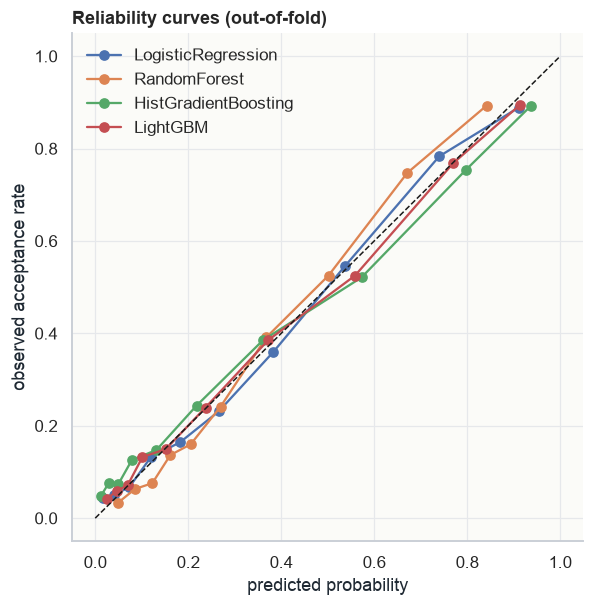

HGB_calibrated cost/resident $3,248 ± 109 | logloss 0.4401


In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
for name in OOF:
    frac, mean_p = calibration_curve(y, OOF[name], n_bins=10, strategy='quantile')
    ax.plot(mean_p, frac, 'o-', label=name)
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_xlabel('predicted probability'); ax.set_ylabel('observed acceptance rate')
ax.set_title('Reliability curves (out-of-fold)'); ax.legend(); plt.show()

models['HGB_calibrated'] = CalibratedClassifierCV(models['HistGradientBoosting'], method='isotonic', cv=3)
folds['HGB_calibrated'], OOF['HGB_calibrated'] = evaluate(models['HGB_calibrated'])
f = folds['HGB_calibrated']
print(f"HGB_calibrated cost/resident ${f.cost.mean():,.0f} ± {f.cost.std():,.0f} | logloss {f.logloss.mean():.4f}")

## 7. Hyper-parameter tuning
LightGBM is tuned with a randomised search. We optimise **log loss**, because the town-cost decision needs good probabilities, then score the tuned model with the town cost. The search uses the same training data that cross-validation later scores, so the tuned model's CV cost is slightly optimistic; a better log loss does not have to mean a lower town cost (compare the two lines printed below).

> 👤 **Section owner:** Shravani Mukkarigari  
> 📌 **Section rules:** Tune on **log loss**, then score the tuned model with `evaluate()`. Always report **before vs after** tuning. Keep searches ≤ 30 iterations so the notebook still runs in time.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `Tuning:` and ends with your name.

In [ ]:
search = RandomizedSearchCV(
    models['LightGBM'],
    {'m__n_estimators': [200, 300, 400, 600, 800], 'm__learning_rate': [0.01, 0.02, 0.03, 0.05],
     'm__num_leaves': [7, 15, 31], 'm__min_child_samples': [20, 30, 50, 80],
     'm__colsample_bytree': [0.6, 0.8, 1.0], 'm__reg_lambda': [0, 1, 5, 10]},
    n_iter=25, scoring='neg_log_loss', cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=-1)
search.fit(X, y)
print('best params:', search.best_params_, '| CV log loss', round(-search.best_score_, 4))
models['LightGBM_tuned'] = search.best_estimator_
folds['LightGBM_tuned'], OOF['LightGBM_tuned'] = evaluate(models['LightGBM_tuned'])
for name in ['LightGBM', 'LightGBM_tuned']:
    f = folds[name]; print(f"{name:15s} cost/resident ${f.cost.mean():,.0f} ± {f.cost.std():,.0f} | logloss {f.logloss.mean():.4f}")

best params: {'m__reg_lambda': 5, 'm__num_leaves': 15, 'm__n_estimators': 400, 'm__min_child_samples': 30, 'm__learning_rate': 0.02, 'm__colsample_bytree': 0.6} | CV log loss 0.4208


LightGBM        cost/resident $3,230 ± 101 | logloss 0.4273
LightGBM_tuned  cost/resident $3,224 ± 105 | logloss 0.4206


## 8. Ensemble
A simple average of the probabilities of the strongest, most different models (linear + boosting). Plain averaging avoids tuning weights on the same data we score on.

> 👤 **Section owner:** Shravani Mukkarigari  
> 📌 **Section rules:** Use simple averaging. Do **not** tune ensemble weights on the same out-of-fold predictions you score them on.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `Ensemble:` and ends with your name.

In [ ]:
from sklearn.base import BaseEstimator, ClassifierMixin

class MeanEnsemble(BaseEstimator, ClassifierMixin):
    """Averages predict_proba of several fitted pipelines."""
    def __init__(self, members): self.members = members
    def fit(self, X, y):
        self.fitted_ = [clone(m).fit(X, y) for m in self.members]; self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.fitted_], axis=0)

models['Ensemble'] = MeanEnsemble([models['LogisticRegression'], models['LightGBM_tuned'], models['HGB_calibrated']])
folds['Ensemble'], OOF['Ensemble'] = evaluate(models['Ensemble'])
f = folds['Ensemble']; print(f"Ensemble cost/resident ${f.cost.mean():,.0f} ± {f.cost.std():,.0f} | AUC {f.auc.mean():.4f}")

Ensemble cost/resident $3,231 ± 107 | AUC 0.8657


## 9. Results
### 9.1 All models: town cost with random variation

> 👤 **Section owner:** Lakshmi Nagaraju Manthri  
> 📌 **Section rules:** Never type numbers by hand; every number comes from code output. When two models differ by less than the fold std, say so (9.1b). Keep the sensitivity check (9.3) up to date.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `Results:` and ends with your name.

,cost/resident (mean),cost/resident (std),cost at 0.5 cut-off,AUC,log loss,saving vs send nobody / resident
LightGBM_tuned,"3,224",105,"3,343",0.8642,0.4206,785
LightGBM,"3,230",101,"3,355",0.8601,0.4273,780
Ensemble,"3,231",107,"3,349",0.8657,0.4195,779
LogisticRegression,"3,235",106,"3,338",0.8637,0.4248,775
RandomForest,"3,235",107,"3,392",0.8582,0.4346,775
HGB_calibrated,"3,248",109,"3,378",0.8541,0.4401,762
HistGradientBoosting,"3,252",110,"3,375",0.8501,0.4556,757


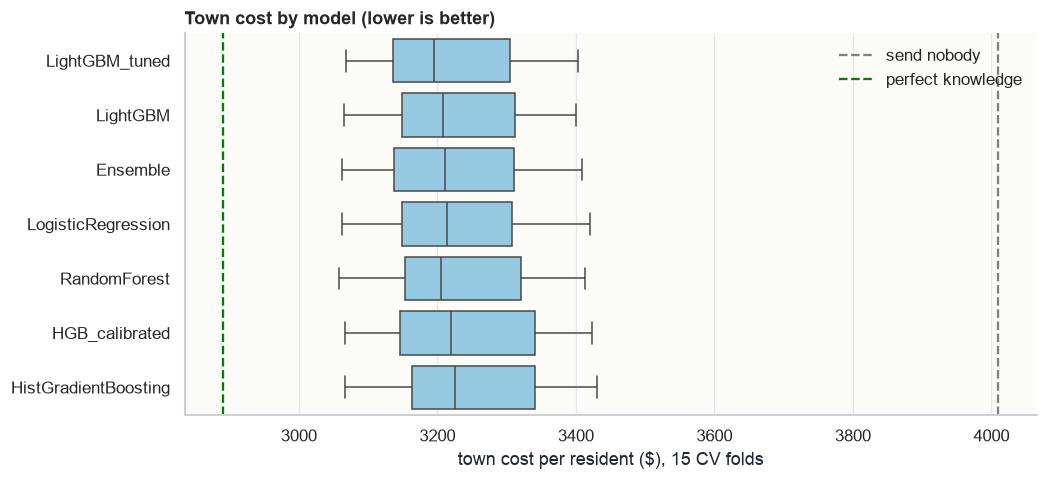

In [ ]:
summary = pd.DataFrame({name: {'cost/resident (mean)': f.cost.mean(), 'cost/resident (std)': f.cost.std(),
                               'cost at 0.5 cut-off': f['cost_at_0.5'].mean(), 'AUC': f.auc.mean(), 'log loss': f.logloss.mean()}
                        for name, f in folds.items()}).T.sort_values('cost/resident (mean)')
summary['saving vs send nobody / resident'] = base_tbl.loc['Send nobody', '$ per resident'] - summary['cost/resident (mean)']
display(summary.style.format({'AUC': '{:.4f}', 'log loss': '{:.4f}'}, precision=0, thousands=','))

order = summary.index.tolist()
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=pd.DataFrame({k: folds[k].cost for k in order}), orient='h', color='#88ccee')
plt.axvline(base_tbl.loc['Send nobody', '$ per resident'], c='grey', ls='--', label='send nobody')
plt.axvline(base_tbl.loc['Perfect knowledge', '$ per resident'], c='green', ls='--', label='perfect knowledge')
plt.xlabel('town cost per resident ($), 15 CV folds'); plt.title('Town cost by model (lower is better)'); plt.legend(); plt.show()

### 9.1b Paired comparison against the best model
All models were scored on **the same 15 folds**, so we can compare them fold by fold. The paired difference removes the fold-to-fold noise shared by all models, and tells us whether a model is *genuinely* worse than the best or just unlucky. This is how the submission order is justified.

In [ ]:
best = summary.index[0]
paired = pd.DataFrame({m: folds[m].cost - folds[best].cost for m in order if m != best})
paired_tbl = pd.DataFrame({'mean extra $/resident vs best': paired.mean(), 'std of difference': paired.std(),
                           'folds where best is cheaper': (paired > 0).sum().astype(str) + ' / 15'})
display(paired_tbl.style.format(precision=1))

,mean extra $/resident vs best,std of difference,folds where best is cheaper
LightGBM,5.4,10.5,9 / 15
Ensemble,6.1,9.3,12 / 15
LogisticRegression,10.4,13.8,11 / 15
RandomForest,10.7,14.4,12 / 15
HGB_calibrated,23.5,18.9,13 / 15
HistGradientBoosting,27.9,14.0,14 / 15


### 9.2 Personal thresholds vs the usual 0.5 cut-off

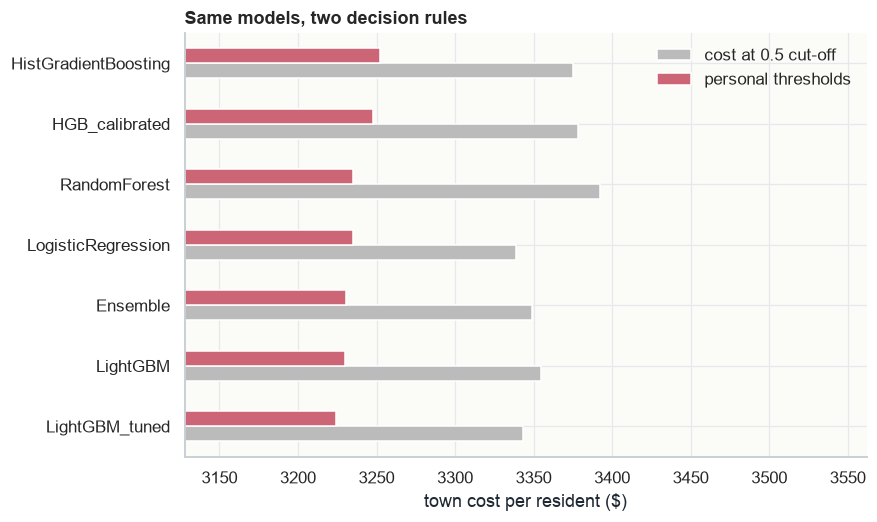

For LightGBM_tuned, personal thresholds save about $564,259 on a town the size of the test set.


In [ ]:
cmp = summary[['cost at 0.5 cut-off', 'cost/resident (mean)']].rename(columns={'cost/resident (mean)': 'personal thresholds'})
cmp.plot(kind='barh', figsize=(8, 5), color=['#bbbbbb', '#cc6677'])
plt.xlabel('town cost per resident ($)'); plt.title('Same models, two decision rules'); plt.xlim(cmp.values.min() * 0.97); plt.show()
best = summary.index[0]
gain = (summary.loc[best, 'cost at 0.5 cut-off'] - summary.loc[best, 'cost/resident (mean)']) * len(test)
print(f'For {best}, personal thresholds save about ${gain:,.0f} on a town the size of the test set.')

### 9.3 Sensitivity to the hospitalisation assumptions
The hospitalisation probabilities are estimates. We re-score every model's out-of-fold probabilities under lower/higher risk and vaccine effectiveness and check how stable the **ranking** is.

In [ ]:
scen = []
for scale in [0.5, 1.0, 2.0]:
    for ve in [0.6, 0.8, 0.9]:
        pa = {k: min(v * scale, P_CAP) for k, v in P_HOSP_AGE.items()}
        pu, pv = hosp_probs(train, p_age=pa, ve=ve)
        costs = {m: town_cost(y, decide(OOF[m], pu, pv), pu, pv) / n for m in OOF}
        ranks = pd.Series(costs).rank().astype(int)
        scen.append({'risk scale': scale, 'VE': ve, **{m: ranks[m] for m in order}})
scen = pd.DataFrame(scen)
display(scen)
print('Models ranked 1st most often:', scen[order].idxmin(axis=1).value_counts().to_dict())
mean_rank = scen[order].mean().sort_values()
print('Mean rank across the 9 scenarios:', mean_rank.round(2).to_dict())
print(f"Order 1 ({order[0]}) has mean rank {mean_rank[order[0]]:.2f}; most robust model: {mean_rank.index[0]} ({mean_rank.iloc[0]:.2f})")

,risk scale,VE,LightGBM_tuned,LightGBM,Ensemble,LogisticRegression,RandomForest,HGB_calibrated,HistGradientBoosting
0,0.5,0.6,1,5,2,3,7,6,4
1,0.5,0.8,2,6,1,4,7,5,3
2,0.5,0.9,3,4,1,5,7,2,6
3,1.0,0.6,2,3,1,5,7,4,6
4,1.0,0.8,1,2,3,5,4,7,6
5,1.0,0.9,1,2,3,4,5,7,6
6,2.0,0.6,1,4,5,2,3,7,6
7,2.0,0.8,2,4,3,1,5,6,7
8,2.0,0.9,3,5,1,2,6,4,7


Models ranked 1st most often: {'LightGBM_tuned': 4, 'Ensemble': 4, 'LogisticRegression': 1}
Mean rank across the 9 scenarios: {'LightGBM_tuned': 1.78, 'Ensemble': 2.22, 'LogisticRegression': 3.44, 'LightGBM': 3.89, 'HGB_calibrated': 5.33, 'RandomForest': 5.67, 'HistGradientBoosting': 5.67}
Order 1 (LightGBM_tuned) has mean rank 1.78; most robust model: LightGBM_tuned (1.78)


## 10. Final ranking and the 5 submission files
The five **distinct** models with the lowest mean town cost are refitted on the full training set, their test probabilities are turned into send / don't-send decisions with the personal thresholds, and saved as `challenge_submission_group_S_order_k.csv`.

> 👤 **Section owner:** Integrator: ____ (choose one)  
> 📌 **Section rules:** Only the integrator runs this, at **15:15** after *Restart and run all*. Exactly 5 **different** files ordered by town cost; the format `assert`s must pass. Canvas upload at **15:40**.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `Final:` and ends with your name.

In [ ]:
import os; os.makedirs('submission', exist_ok=True)   # the 5 files go in their own folder
PU_test, PV_test = hosp_probs(test)
ranking = []
for rank, name in enumerate(order[:5], 1):
    q_test = clone(models[name]).fit(X, y).predict_proba(X_test)[:, 1]
    sent = decide(q_test, PU_test, PV_test)
    fname = f'challenge_submission_group_{GROUP}_order_{rank}.csv'
    sub = pd.DataFrame({ID: test[ID].values, TARGET: sent.astype(example[TARGET].dtype)})
    # format checks against the example file
    assert list(sub.columns) == list(example.columns) and len(sub) == len(example)
    assert sub[ID].equals(example[ID]) and sub[TARGET].isin([0, 1]).all()
    sub.to_csv(os.path.join('submission', fname), index=False)
    ranking.append({'order': rank, 'file': fname, 'model': name,
                    'CV cost/resident': round(summary.loc[name, 'cost/resident (mean)']),
                    'CV std': round(summary.loc[name, 'cost/resident (std)']),
                    'vaccines sent': int(sent.sum()), 'share sent': round(sent.mean(), 3)})
ranking = pd.DataFrame(ranking); os.makedirs('results', exist_ok=True); ranking.to_csv('results/ranking.csv', index=False); ranking

,order,file,model,CV cost/resident,CV std,vaccines sent,share sent
0,1,challenge_submission_group_S_order_1.csv,LightGBM_tuned,3224,105,1606,0.338
1,2,challenge_submission_group_S_order_2.csv,LightGBM,3230,101,1607,0.338
2,3,challenge_submission_group_S_order_3.csv,Ensemble,3231,107,1639,0.345
3,4,challenge_submission_group_S_order_4.csv,LogisticRegression,3235,106,1661,0.350
4,5,challenge_submission_group_S_order_5.csv,RandomForest,3235,107,1625,0.342


**In Colab:** the next cell zips `submission/` (the 5 files for Canvas) and `results/ranking.csv` and downloads them to your computer. Locally it only prints where the files are.

In [ ]:
import shutil
if IN_COLAB:
    from google.colab import files
    os.makedirs('download', exist_ok=True)
    shutil.copytree('submission', 'download/submission', dirs_exist_ok=True)
    shutil.copy('results/ranking.csv', 'download/ranking.csv')
    shutil.make_archive('GroupS_submission', 'zip', 'download')
    files.download('GroupS_submission.zip')
else:
    print('Submission files:', sorted(os.listdir('submission')), '| ranking: results/ranking.csv')

Submission files: ['challenge_submission_group_S_order_1.csv', 'challenge_submission_group_S_order_2.csv', 'challenge_submission_group_S_order_3.csv', 'challenge_submission_group_S_order_4.csv', 'challenge_submission_group_S_order_5.csv'] | ranking: results/ranking.csv


## 11. Explainable AI (first version, to be extended after the hackathon)
Shapley values from the order-1 LightGBM model: which features drive the predicted acceptance probability.

> 👤 **Section owner:** Varun Kumar Kashetty  
> 📌 **Section rules:** May continue after 16:00 (XAI and figure styling only). Rubric wants **several XAI techniques for all models** (e.g. SHAP + permutation importance + LogReg coefficients) and a critical comparison.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `XAI:` and ends with your name.

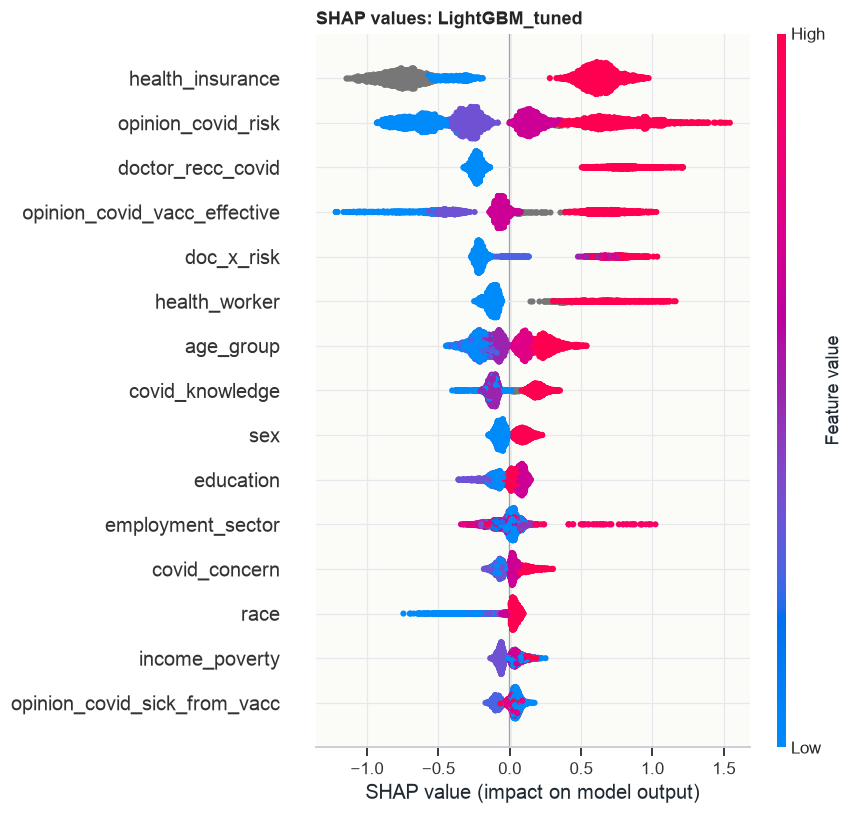

In [ ]:
import shap
shap_name = order[0] if order[0] in ('LightGBM', 'LightGBM_tuned') else 'LightGBM_tuned'   # explain the submitted order-1 model
lgb_pipe = clone(models[shap_name]).fit(X, y)
Xt = pd.DataFrame(lgb_pipe.named_steps['p'].transform(X), columns=CAT + NUM)
sv = shap.TreeExplainer(lgb_pipe.named_steps['m']).shap_values(Xt)
sv = sv[1] if isinstance(sv, list) else sv
shap.summary_plot(sv, Xt, max_display=15, show=False); plt.title(f'SHAP values: {shap_name}'); plt.tight_layout(); plt.show()

## 12. Critical analysis

> 👤 **Section owner:** Varun Kumar Kashetty (with everyone)  
> 📌 **Section rules:** Every claim must point to a figure/table in this notebook. Cover successes, failures, limitations and the AI assumptions.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `Analysis:` and ends with your name.

In [ ]:
b = summary.iloc[0]; noise = b['cost/resident (std)']
gap = summary['cost/resident (mean)'].iloc[1] - b['cost/resident (mean)']
print(f"* Best model: {summary.index[0]} at ${b['cost/resident (mean)']:,.0f} per resident (± {noise:,.0f} across folds).")
print(f"* Gap to the 2nd model is ${gap:,.0f}, {'smaller' if gap < noise else 'larger'} than the fold-to-fold noise, "
      f"so the top of the ranking is {'not clearly separated' if gap < noise else 'clearly separated'}.")
print(f"* Saving vs sending nobody: ${b['saving vs send nobody / resident']:,.0f} per resident; "
      f"perfect knowledge would cost ${base_tbl.loc['Perfect knowledge', '$ per resident']:,.0f}.")

* Best model: LightGBM_tuned at $3,224 per resident (± 105 across folds).
* Gap to the 2nd model is $5, smaller than the fold-to-fold noise, so the top of the ranking is not clearly separated.
* Saving vs sending nobody: $785 per resident; perfect knowledge would cost $2,891.


**Points to discuss (check against the outputs above and rewrite in the team's own words):**
* **Why AUC is not the target.** Models with almost the same AUC differ in town cost, and the cheapest decision rule is not the most accurate one. The decision needs well-calibrated probabilities, which is why tuning used log loss and calibration was checked (section 6).
* **The decision rule matters more than the model.** Personal thresholds save far more than switching between models (section 9.2 vs 9.1).
* **The top models are within noise.** The paired comparison (9.1b) and the sensitivity table (9.3) show that the order of the top files is close; say this openly rather than presenting order 1 as clearly best.
* **The hospitalisation estimates are the weakest link.** They come from generative AI, and section 9.3 shows the ranking among the top models changes when they change. The lecturers will score with their own values.
* **Data quality.** Two opinion scales contained invalid 0 codes, treated as missing (1.1). `doctor_recc_covid` has no missing values, unlike the other datasets, so missing answers may have been recorded as "not recommended".
* **Pre-processing evidence.** Section 5.1 measures, fold by fold, whether missing-value indicators and the engineered features actually lower the cost.
* **Limitations:** a survey of under 5,000 people; stated intentions may not match behaviour; one vaccine effectiveness for everyone; residents paid in cash are assumed to stay unvaccinated; the tuned model's CV cost is slightly optimistic.